# Figure 5 — Python workflows and saved results

SpMap transfers IMC-defined tissue and peritumoral niche labels to H&E tiles and summarizes predicted PIR- and PSM-Niche tiles as an immune-stromal ratio (ISR). This display notebook presents the six Figure 5 Python sources alongside the saved publication figures and their current captions.

The reading order follows reference preparation, paired CONCH features, grouped model evaluation and WSI inference; Figure 5B count preparation and plotting; public artifact export; and supplementary OOF metrics and matched-patient ISR correlation. Code cells retain the original scripts and source line ranges.

Read the [Figure 5 README](README.md) for input contracts, the [Figure 5 report](Figure5.md) for the saved results, and the [figure display guide](../../docs/rmd_display.md) for the report collection. Captions are from [Figure5.Rmd](Figure5.Rmd).

## Inputs, outputs, and analysis units

Reference inputs comprise registered IMC structures, selected tumor-core and other peritumoral ROIs, matched H&E images, paired CONCH representations, and tile/split manifests. Classes are `0=TC`, `1=PIR`, `2=PSM`, and `3=OTHER_PT`. Reference tiles measure 256 × 256 pixels and are nested within source structures or ROIs through `parent_id`.

Workflow outputs include reference manifests, paired features, fold checkpoints and evaluation tables, retained WSI tile predictions, and WSI ISR. Count summaries use tiles and parent groups; classification uses tiles; fold and seed summaries describe model evaluations. The common-holdout evaluations share the same reserved tiles. ISR correlation uses one paired observation per matched patient.


## 1. SpMap reference, training, and WSI workflow

[02_run_spmap_workflow.py](02_run_spmap_workflow.py) connects the shared [SpMap modules](../../src/spmap/README.md) in scientific workflow order. `CONFIG` specifies stage inputs, adapters, output paths, and stage selection. Inference inputs include WSI paths and level, a selected checkpoint/model identity, and Macenko and CONCH adapters.

The model uses paired 768- and 512-dimensional CONCH representations in a `1280 → 450 → 4` MLP with ReLU and dropout 0.25. Parent groups define the development/common-holdout split and five-fold validation within development. Training features reside in RAM during seed and fold loops; predictions retain their tile and model identities.


### Imports, model parameters, and stage configuration

The source declares shared dependencies, fixed split and training settings, and the reference, training, and inference configuration.

[Source: 02_run_spmap_workflow.py (lines 1–102)](02_run_spmap_workflow.py)


In [ ]:
#!/usr/bin/env python3
"""Run the Figure 5 SpMap workflow from editable configuration.

Target/purpose: call the shared SpMap reference, preprocessing, CONCH,
grouped split/training/evaluation, WSI-inference, and ISR APIs. Inputs: the
paths and adapter callables set in ``CONFIG``. Outputs: selected manifests,
paired reference features, fold checkpoints/metrics, and WSI prediction/ISR
tables. Ordered workflow: build reference tiles, preprocess and extract CONCH
features, build grouped splits and train/evaluate folds, then infer WSI tiles
and aggregate ISR. The ``enabled`` mapping selects the stages for each run.
"""

from __future__ import annotations

import importlib
import json
import sys
from pathlib import Path
from typing import Any, Callable

import numpy as np
import pandas as pd
import torch


CODE_ROOT = Path(__file__).resolve().parents[2]
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

from src.spmap.conch_features import ConchFeatureExtractor
from src.spmap.inference import load_checkpoint, predict_wsi_tiles
from src.spmap.isr import aggregate_isr
from src.spmap.mlp import (
    FeatureDataset,
    InMemoryFeatureStore,
    checkpoint_manifest,
    evaluate_predictions,
    prediction_frame,
    require_cuda,
    set_seed,
    summarize_oof_predictions,
    summarize_training_seed_variability,
    train_fold,
)
from src.spmap.preprocessing import VahadaneTrainingNormalizer, preprocess_training_tile
from src.spmap.reference_tiles import (
    build_complete_tile_manifest,
    build_structure_bboxes,
    extract_tile,
)
from src.spmap.splits import assert_figure5_training_contract, build_grouped_splits
from src.spmap.wsi import iter_wsi_tiles, open_wsi


SPLIT_SEED = 42
TRAINING_SEEDS = (24, 101, 202, 303, 404)
FOLDS = 5
EPOCHS = 100
BATCH_SIZE = 256
NUM_WORKERS = 6
GPU_INDEX = 0

# Set paths and adapter callables, then select workflow stages with ``enabled``.
CONFIG: dict[str, Any] = {
    "enabled": {
        "build_reference_manifest": False,
        "extract_reference_conch": False,
        "train_evaluate": False,
        "infer_wsi": False,
    },
    "reference": {
        "structure_cells_csv": None,
        "selected_regions_csv": None,
        "image_sizes": {},
        "manifest_output": Path("/path/to/reference_tile_manifest.csv"),
        "image_loader": None,
        "conch_checkpoint": None,
        "conch_model_loader": None,
        "conch_preprocess": None,
        "conch_forward_representations": None,
        "feature_output": Path("/path/to/reference_conch_features.npz"),
    },
    "training": {
        "tile_manifest_csv": Path("/path/to/canonical_tile_manifest.csv"),
        "feature_tar_root": Path("/path/to/03_conch_features"),
        "output_dir": Path("/path/to/spmap_training"),
    },
    "inference": {
        "wsi_paths": [],
        "checkpoint": Path("/path/to/checkpoint.pt"),
        "model_id": "replace_with_checkpoint_identifier",
        "output_dir": Path("/path/to/spmap_wsi_inference"),
        "wsi_level": 0,
        "macenko_normalizer": None,
        "conch_checkpoint": None,
        "conch_model_loader": None,
        "conch_preprocess": None,
        "conch_forward_representations": None,
    },
}




### Workflow interfaces and evaluation exports

Related helpers resolve configured adapters and paths and export classification, per-class, and confusion summaries from the same prediction rows.

[Source: 02_run_spmap_workflow.py (lines 103–199)](02_run_spmap_workflow.py)


In [ ]:
def resolve_callable(specification: str | Callable[..., Any] | None, name: str) -> Callable[..., Any]:
    """Resolve a configured adapter callable or fail with its configuration name.

    Parameters: ``specification`` is either a callable or a ``module:attribute``
    string, and ``name`` identifies the required configuration field.
    Returns: the configured callable.
    """
    # Normalize direct callables and import specifications to one adapter interface.
    if callable(specification):
        return specification
    if isinstance(specification, str) and ":" in specification:
        module_name, attribute_name = specification.split(":", maxsplit=1)
        resolved = getattr(importlib.import_module(module_name), attribute_name)
        if callable(resolved):
            return resolved
    raise ValueError(f"{name} must be a callable or 'module:attribute' string")


def require_file(path: str | Path | None, name: str) -> Path:
    """Return an existing configured file path.

    Parameters: ``path`` is a configured path-like value and ``name`` labels it.
    Returns: the existing path as a ``Path`` instance.
    """
    # Convert configured file values once so downstream stages receive concrete paths.
    if path is None:
        raise ValueError(f"{name} is required")
    resolved = Path(path)
    if not resolved.is_file():
        raise FileNotFoundError(f"{name} does not exist: {resolved}")
    return resolved


def require_directory(path: str | Path | None, name: str) -> Path:
    """Return an existing configured directory path.

    Parameters: ``path`` is a configured path-like value and ``name`` labels it.
    Returns: the existing directory as a ``Path`` instance.
    """
    # Convert configured directory values once at the workflow boundary.
    if path is None:
        raise ValueError(f"{name} is required")
    resolved = Path(path)
    if not resolved.is_dir():
        raise NotADirectoryError(f"{name} is not a directory: {resolved}")
    return resolved


def prepare_empty_output_directory(path: str | Path, name: str) -> Path:
    """Create or validate an empty output directory for a new run.

    Parameters: ``path`` is the configured output location and ``name`` labels
    the directory in error messages.
    Returns: the empty directory as a ``Path`` instance.
    """
    # Each training or inference invocation owns one initially empty output directory.
    output = Path(path)
    if output.exists():
        if not output.is_dir():
            raise NotADirectoryError(f"{name} is not a directory: {output}")
        if next(output.iterdir(), None) is not None:
            raise FileExistsError(f"{name} must be empty for a new run: {output}")
    else:
        output.mkdir(parents=True)
    return output


def write_prediction_artifacts(
    predictions: pd.DataFrame,
    output_dir: Path,
    prefix: str,
) -> dict[str, object]:
    """Write classification, per-class, and confusion artifacts for predictions.

    Parameters: ``predictions`` is one fold's validated prediction table,
    ``output_dir`` is its seed/fold directory, and ``prefix`` identifies the
    validation or common-holdout evaluation.
    Returns: the classification metric mapping written for the evaluation.
    """
    # Derive all metric and confusion exports from the same prediction rows.
    summary = summarize_oof_predictions([predictions])
    pd.DataFrame([summary["metrics"]]).to_csv(
        output_dir / f"{prefix}_classification_metrics.csv", index=False
    )
    summary["per_class_metrics"].to_csv(
        output_dir / f"{prefix}_per_class_metrics.csv", index=False
    )
    summary["confusion_counts"].to_csv(
        output_dir / f"{prefix}_confusion_counts.csv", index_label="true_class"
    )
    summary["confusion_row_normalized"].to_csv(
        output_dir / f"{prefix}_confusion_row_proportions.csv",
        index_label="true_class",
    )
    return summary["metrics"]




### Reference structures and complete tile manifests

Registered structure coordinates and selected regions are combined into a manifest of complete reference tiles.

[Source: 02_run_spmap_workflow.py (lines 200–235)](02_run_spmap_workflow.py)


In [ ]:
def build_reference_manifest(config: dict[str, Any]) -> pd.DataFrame:
    """Build the caller-selected SpMap reference-tile manifest.

    Parameters: ``config`` provides optional registered-cell and selected-region
    CSVs, image dimensions by source image ID, and a manifest output path.
    Returns: the complete-tile manifest written to the configured CSV.
    """
    # Map registered structures and selected regions into one reference-region stream.
    reference = config["reference"]
    region_frames: list[pd.DataFrame] = []
    cells_path = reference["structure_cells_csv"]
    if cells_path is not None:
        cells = pd.read_csv(require_file(cells_path, "structure_cells_csv"))
        image_sizes = reference["image_sizes"]
        for source_image_id, group in cells.groupby("source_image_id", sort=False):
            if str(source_image_id) not in image_sizes:
                raise ValueError(f"image_sizes lacks source image {source_image_id}")
            region_frames.append(
                build_structure_bboxes(
                    group,
                    image_size=tuple(image_sizes[str(source_image_id)]),
                )
            )
    regions_path = reference["selected_regions_csv"]
    if regions_path is not None:
        region_frames.append(pd.read_csv(require_file(regions_path, "selected_regions_csv")))
    if not region_frames:
        raise ValueError("Provide structure_cells_csv and/or selected_regions_csv")
    # Complete tiling is applied after all configured region sources share one schema.
    manifest = build_complete_tile_manifest(pd.concat(region_frames, ignore_index=True))
    output = Path(reference["manifest_output"])
    output.parent.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(output, index=False)
    return manifest




### Reference preprocessing and paired CONCH extraction

The feature stage preprocesses selected tiles and preserves alignment between retained tile IDs and the 768- and 512-dimensional arrays.

[Source: 02_run_spmap_workflow.py (lines 236–306)](02_run_spmap_workflow.py)


In [ ]:
def create_conch_extractor(config: dict[str, Any]) -> ConchFeatureExtractor:
    """Instantiate the CUDA-only CONCH adapter from editable configuration.

    Parameters: ``config`` provides a checkpoint and model/preprocess/forward
    adapter callables for a compatible CONCH v1 implementation.
    Returns: a ready CUDA ``ConchFeatureExtractor``.
    """
    # Bind the checkpoint and three CONCH adapters to the fixed workflow GPU.
    return ConchFeatureExtractor(
        model_loader=resolve_callable(config["conch_model_loader"], "conch_model_loader"),
        checkpoint=str(require_file(config["conch_checkpoint"], "conch_checkpoint")),
        preprocess=resolve_callable(config["conch_preprocess"], "conch_preprocess"),
        forward_representations=resolve_callable(
            config["conch_forward_representations"],
            "conch_forward_representations",
        ),
        gpu_index=GPU_INDEX,
    )


def extract_reference_conch(config: dict[str, Any]) -> None:
    """Preprocess selected reference tiles and save paired CONCH arrays.

    Parameters: ``config`` provides the reference manifest, RGB image loader,
    CONCH adapters, and paired-feature NPZ output path.
    Returns: no value; writes a compressed NPZ with tile IDs and 768/512 arrays.
    """
    # Initialize preprocessing and feature extraction once for the full manifest.
    reference = config["reference"]
    manifest = pd.read_csv(require_file(reference["manifest_output"], "manifest_output"))
    image_loader = resolve_callable(reference["image_loader"], "image_loader")
    normalizer = VahadaneTrainingNormalizer()
    extractor = create_conch_extractor(reference)
    images: dict[str, np.ndarray] = {}
    kept_ids: list[str] = []
    kept_images: list[np.ndarray] = []
    # Cache each source image and retain tile IDs in exact processed-image order.
    for tile in manifest.itertuples(index=False):
        source_image_id = str(tile.source_image_id)
        if source_image_id not in images:
            images[source_image_id] = np.asarray(image_loader(source_image_id))
        processed = preprocess_training_tile(
            extract_tile(images[source_image_id], pd.Series(tile._asdict())),
            normalizer=normalizer,
        )
        if processed.kept:
            kept_ids.append(str(tile.tile_id))
            kept_images.append(processed.image)
    if not kept_ids:
        raise ValueError("Reference preprocessing retained no tiles")

    # Batch extraction preserves alignment between retained IDs and both representations.
    semantic_batches, alignment_batches = [], []
    for start in range(0, len(kept_ids), BATCH_SIZE):
        features = extractor.extract(
            kept_ids[start : start + BATCH_SIZE],
            kept_images[start : start + BATCH_SIZE],
        )
        semantic_batches.append(features.semantic_768)
        alignment_batches.append(features.alignment_512)
    # Export the paired feature matrices with their shared tile-ID axis.
    output = Path(reference["feature_output"])
    output.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        output,
        tile_ids=np.asarray(kept_ids, dtype=str),
        semantic_768=np.concatenate(semantic_batches, axis=0),
        alignment_512=np.concatenate(alignment_batches, axis=0),
    )




### Grouped training and model evaluation

One feature store supports five folds across the specified seeds. Each selected checkpoint supplies validation and common-holdout predictions, followed by pooled OOF and seed summaries.

[Source: 02_run_spmap_workflow.py (lines 307–455)](02_run_spmap_workflow.py)


In [ ]:
def train_and_evaluate(config: dict[str, Any]) -> None:
    """Run five ordered fold sequences using one RAM-resident feature store.

    Parameters: ``config`` provides the canonical manifest, CONCH tar root, and
    output directory. Fixed split/training parameters are module constants.
    Returns: no value; writes seed/fold checkpoints and evaluation artifacts,
    seed-24 S11A/B inputs, and five-seed S11C summaries.
    """
    # Create the grouped development, fold, and common-holdout evaluation structure.
    training = config["training"]
    output_dir = prepare_empty_output_directory(
        training["output_dir"], "training.output_dir"
    )
    manifest = pd.read_csv(require_file(training["tile_manifest_csv"], "tile_manifest_csv"))
    splits = build_grouped_splits(
        manifest,
        n_folds=FOLDS,
        seed=SPLIT_SEED,
    )
    assert_figure5_training_contract(
        manifest,
        splits["development"],
        splits["internal_holdout"],
    )
    splits["development"].to_csv(output_dir / "development.csv", index=False)
    splits["internal_holdout"].to_csv(output_dir / "internal_holdout.csv", index=False)

    # Load all required tar-shard features once before any seed or fold starts.
    feature_store = InMemoryFeatureStore(
        require_directory(training["feature_tar_root"], "feature_tar_root"),
        [splits["development"], splits["internal_holdout"]],
    )
    # Repeat the fixed folds across seeds while sharing the RAM-resident feature store.
    seed_summaries: dict[int, dict[str, object]] = {}
    for seed in TRAINING_SEEDS:
        seed_dir = output_dir / f"seed_{seed}"
        seed_dir.mkdir()
        set_seed(seed)
        validation_predictions = []
        validation_metrics, holdout_metrics = [], []
        # Each fold trains once, freezes its selected model, and evaluates two disjoint sets.
        for fold_data in splits["folds"]:
            fold = int(fold_data["fold"])
            fold_dir = seed_dir / f"fold_{fold}"
            fold_dir.mkdir()
            result = train_fold(
                fold_data["train"],
                fold_data["validation"],
                feature_store,
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                seed=seed,
                gpu_index=GPU_INDEX,
                num_workers=NUM_WORKERS,
                reset_seed=False,
            )
            model_id = f"spmap_seed{seed}_fold{fold}"
            torch.save(result.model.state_dict(), fold_dir / "best_checkpoint.pt")
            result.history.to_csv(fold_dir / "training_history.csv", index=False)
            with (fold_dir / "checkpoint_manifest.json").open("x", encoding="utf-8") as handle:
                json.dump(
                    checkpoint_manifest(
                        model_id=model_id,
                        selected_epoch=result.selected_epoch,
                        fold=fold,
                        seed=seed,
                    ),
                    handle,
                    indent=2,
                    sort_keys=True,
                )
                handle.write("\n")

            # Prepare validation and common-holdout predictions from the same fold checkpoint.
            validation = prediction_frame(
                result.model,
                FeatureDataset(fold_data["validation"], feature_store),
                batch_size=BATCH_SIZE,
                gpu_index=GPU_INDEX,
                num_workers=NUM_WORKERS,
            )
            holdout = prediction_frame(
                result.model,
                FeatureDataset(splits["internal_holdout"], feature_store),
                batch_size=BATCH_SIZE,
                gpu_index=GPU_INDEX,
                num_workers=NUM_WORKERS,
            )
            validation.to_csv(fold_dir / "validation_predictions.csv", index=False)
            holdout.to_csv(fold_dir / "common_holdout_predictions.csv", index=False)
            write_prediction_artifacts(validation, fold_dir, "validation")
            write_prediction_artifacts(holdout, fold_dir, "common_holdout")
            validation_predictions.append(validation)
            validation_metrics.append({"fold": fold, **evaluate_predictions(validation)})
            holdout_metrics.append({"fold": fold, **evaluate_predictions(holdout)})

        # Consolidate fold metrics and pooled out-of-fold predictions for this seed.
        fold_summary = pd.DataFrame(validation_metrics).drop(columns="confusion_matrix")
        holdout_summary = pd.DataFrame(holdout_metrics).drop(columns="confusion_matrix")
        fold_summary.to_csv(seed_dir / "fold_validation_metrics.csv", index=False)
        holdout_summary.to_csv(seed_dir / "common_holdout_metrics.csv", index=False)
        if seed == TRAINING_SEEDS[0]:
            fold_summary.to_csv(output_dir / "fold_validation_metrics.csv", index=False)
            holdout_summary.to_csv(output_dir / "common_holdout_metrics.csv", index=False)

        oof = summarize_oof_predictions(validation_predictions)
        oof["pooled_predictions"].to_csv(seed_dir / "oof_predictions.csv", index=False)
        pd.DataFrame([oof["metrics"]]).to_csv(
            seed_dir / "oof_classification_metrics.csv", index=False
        )
        oof["per_class_metrics"].to_csv(
            seed_dir / "oof_per_class_metrics.csv", index=False
        )
        oof["confusion_counts"].to_csv(
            seed_dir / "oof_confusion_counts.csv", index_label="true_class"
        )
        oof["confusion_row_normalized"].to_csv(
            seed_dir / "oof_confusion_row_proportions.csv", index_label="true_class"
        )
        seed_summaries[seed] = oof

    # Export the prespecified seed panels and cross-seed variability tables.
    seed_24 = seed_summaries[TRAINING_SEEDS[0]]
    seed_24["confusion_counts"].to_csv(
        output_dir / "confusion_counts.csv", index_label="true_class"
    )
    seed_24["confusion_row_normalized"].to_csv(
        output_dir / "confusion_row_proportions.csv", index_label="true_class"
    )
    seed_class_metrics = pd.concat(
        [
            summary["per_class_metrics"].assign(seed=seed)
            for seed, summary in seed_summaries.items()
        ],
        ignore_index=True,
    )
    seed_class_metrics = seed_class_metrics[
        ["seed", *[column for column in seed_class_metrics.columns if column != "seed"]]
    ]
    seed_overall_metrics = pd.DataFrame(
        [{"seed": seed, **summary["metrics"]} for seed, summary in seed_summaries.items()]
    )
    seed_class_metrics.to_csv(output_dir / "seed_class_metrics.csv", index=False)
    seed_overall_metrics.to_csv(output_dir / "seed_overall_metrics.csv", index=False)
    summarize_training_seed_variability(seed_overall_metrics).to_csv(
        output_dir / "training_seed_variability.csv", index=False
    )




### WSI inference and ISR aggregation

Retained WSI tiles receive class probabilities and predicted labels. The same prediction table supplies per-WSI class counts and the PIR/PSM tile-count ratio.

[Source: 02_run_spmap_workflow.py (lines 456–501)](02_run_spmap_workflow.py)


In [ ]:
def infer_wsi_and_aggregate_isr(config: dict[str, Any]) -> None:
    """Predict configured WSIs and aggregate their literal PIR/PSM ISR.

    Parameters: ``config`` provides WSI paths, one checkpoint/model ID, Macenko
    and CONCH adapters, and an output directory.
    Returns: no value; writes retained-tile prediction and WSI ISR CSVs.
    """
    # Initialize one normalizer, extractor, and checkpoint for all configured WSIs.
    inference = config["inference"]
    output_dir = prepare_empty_output_directory(
        inference["output_dir"], "inference.output_dir"
    )
    paths = [require_file(path, "wsi_paths item") for path in inference["wsi_paths"]]
    if not paths:
        raise ValueError("inference.wsi_paths must contain at least one WSI")
    normalizer = resolve_callable(inference["macenko_normalizer"], "macenko_normalizer")
    extractor = create_conch_extractor(inference)
    model = load_checkpoint(require_file(inference["checkpoint"], "checkpoint"), gpu_index=GPU_INDEX)
    # Keep each slide open only while its retained tiles are generated and predicted.
    prediction_frames = []
    for path in paths:
        slide = open_wsi(path)
        try:
            prediction_frames.append(
                predict_wsi_tiles(
                    iter_wsi_tiles(
                        slide,
                        wsi_id=path.stem,
                        level=int(inference["wsi_level"]),
                        macenko_normalizer=normalizer,
                    ),
                    feature_extractor=extractor,
                    model=model,
                    model_id=str(inference["model_id"]),
                    batch_size=BATCH_SIZE,
                    gpu_index=GPU_INDEX,
                )
            )
        finally:
            slide.close()
    # Aggregate WSI ISR from the same concatenated tile predictions that are exported.
    predictions = pd.concat(prediction_frames, ignore_index=True)
    predictions.to_csv(output_dir / "wsi_tile_predictions.csv", index=False)
    aggregate_isr(predictions).to_csv(output_dir / "wsi_isr.csv", index=False)




### Ordered stage dispatch

The script entry point dispatches enabled stages in reference, feature, training, and inference order.

[Source: 02_run_spmap_workflow.py (lines 502–525)](02_run_spmap_workflow.py)


In [ ]:
def run(config: dict[str, Any]) -> None:
    """Execute each explicitly enabled Figure 5 SpMap stage in workflow order.

    Parameters: ``config`` is the editable ``CONFIG`` mapping at module scope.
    Returns: no value; creates outputs only for enabled stages and fails fast on
    missing CUDA, invalid adapters, missing inputs, or retained contract checks.
    """
    # Enforce CUDA before dispatching enabled stages in their scientific workflow order.
    enabled = config["enabled"]
    cuda_stages = ("extract_reference_conch", "train_evaluate", "infer_wsi")
    if any(enabled[stage] for stage in cuda_stages):
        require_cuda(GPU_INDEX)
    if enabled["build_reference_manifest"]:
        build_reference_manifest(config)
    if enabled["extract_reference_conch"]:
        extract_reference_conch(config)
    if enabled["train_evaluate"]:
        train_and_evaluate(config)
    if enabled["infer_wsi"]:
        infer_wsi_and_aggregate_isr(config)


if __name__ == "__main__":
    run(CONFIG)


## Saved whole-slide results — Supplementary Figure 12

The [inference module](../../src/spmap/inference.py) retains tile coordinates, model identity, probabilities, and class labels. The saved examples pair eight spatial prediction maps with H&E views; tumor-region agreement uses each of 33 WSIs as the observational unit.

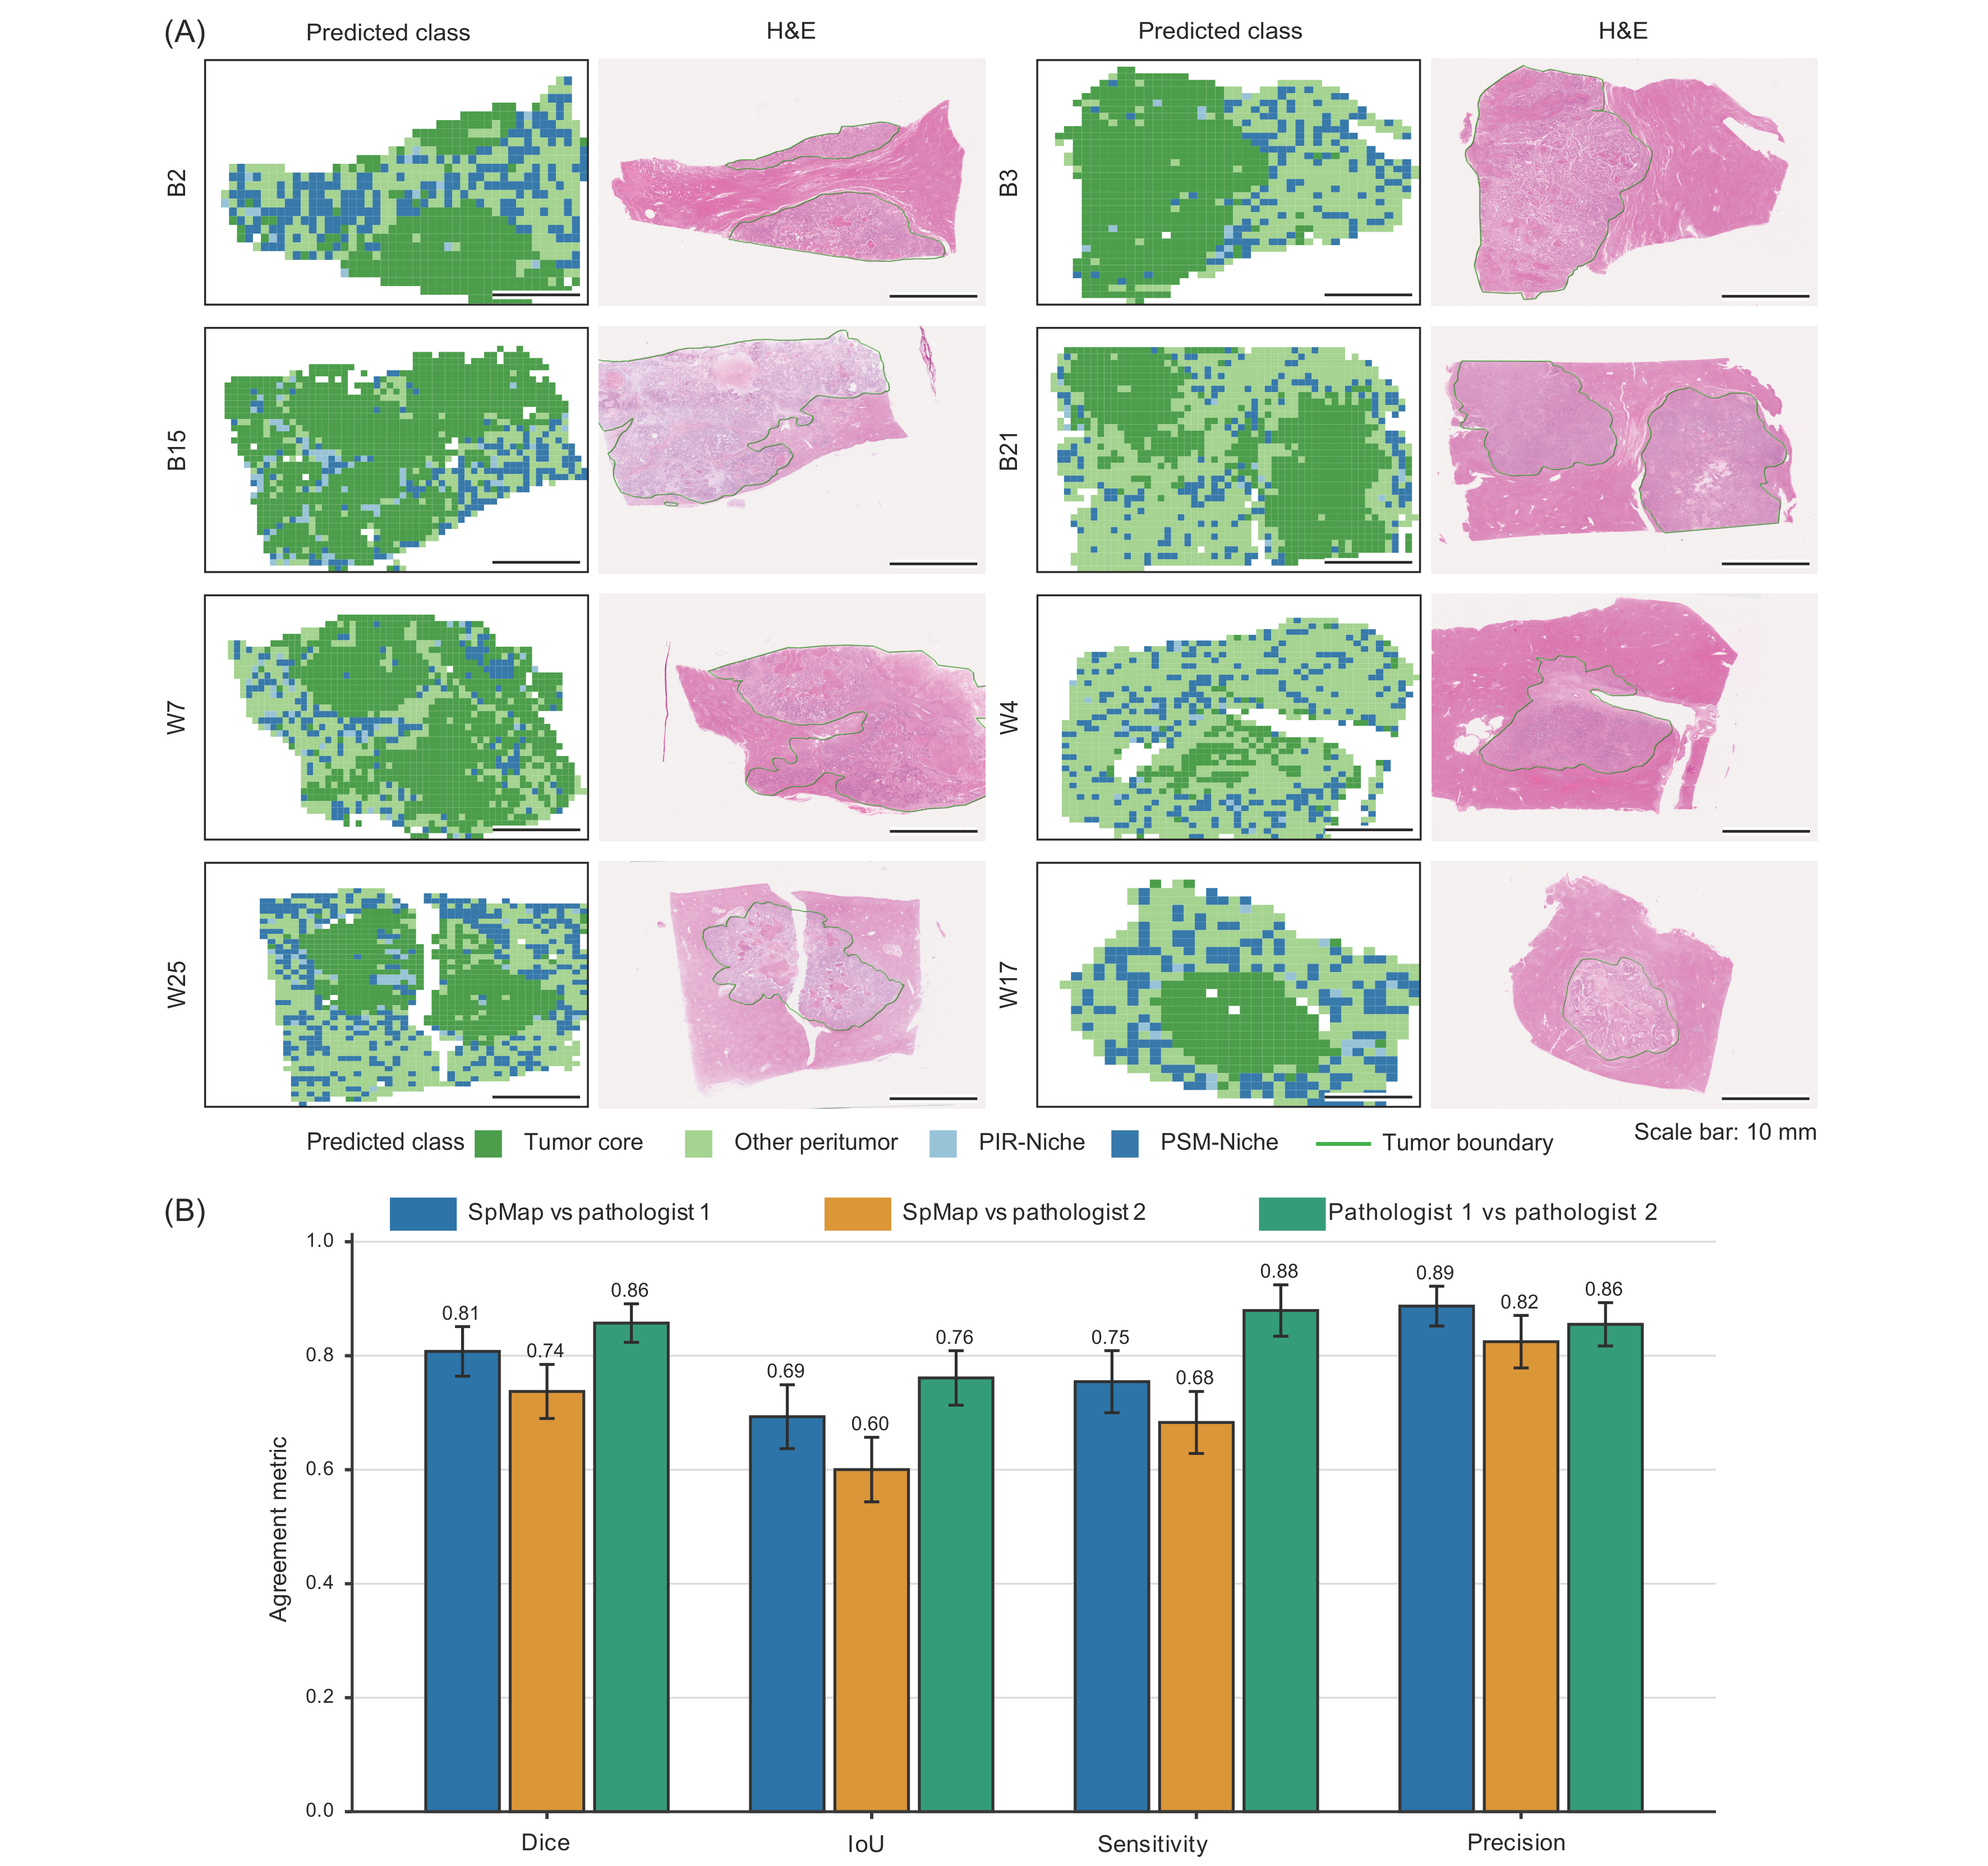

**Supplementary Figure 12. SpMap predictions on whole-slide H&E images.** (A) Predicted tumor core, other peritumor, PIR-Niche, and PSM-Niche regions with matched H&E images for B2, B3, B15, B21, W7, W4, W25, and W17. Green outlines show tumor boundaries delineated by Pathologist 1; scale bars, 10 mm. (B) Dice, intersection over union (IoU), sensitivity, and precision for SpMap versus each pathologist and for interobserver agreement. Bars show WSI-level means and error bars show two-sided 95% t confidence intervals. Sensitivity and precision use the corresponding pathologist as reference for model comparisons and Pathologist 1 as reference for the interobserver comparison.

[Original tumor-region agreement panel PDF](report_assets/wsi_pathologist_agreement.pdf).


## 2. Figure 5B reference counts

[01_prepare_panel_b_counts.py](01_prepare_panel_b_counts.py) reads the canonical tile-label, development, and internal-holdout manifests. It reconciles tile labels and parent groups and writes `Figure5B_training_count_provenance.tsv`, distinguishing class counts, split tile counts, and split parent-group counts.

The documented input contract contains 61,628 reference tiles: 23,894 TC, 9,690 PIR, 9,060 PSM, and 18,984 other PT. The development and common-holdout subsets contain 49,001 and 12,627 tiles, respectively.


### Count inputs and class definitions

The configuration identifies the three source manifests and the count-table output.

[Source: 01_prepare_panel_b_counts.py (lines 1–36)](01_prepare_panel_b_counts.py)


In [ ]:
#!/usr/bin/env python3
"""Prepare the Figure 5B training-count table.

Target/purpose: report canonical four-class tile and grouped-split counts.
Inputs: canonical tile, development, and internal-holdout CSV manifests selected
in ``CONFIG``. Outputs: one Figure5B TSV selected in ``CONFIG``. Ordered
workflow: read and validate manifests, verify split coverage and group
disjointness, build the training-count table, then write the TSV.
"""

from __future__ import annotations

import sys
from pathlib import Path

import pandas as pd


CODE_ROOT = Path(__file__).resolve().parents[2]
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

from src.spmap.splits import assert_figure5_training_contract, assert_group_disjoint


CLASS_NAMES = {0: "TC", 1: "PIR", 2: "PSM", 3: "OTHER_PT"}

# Edit these paths before running this interactive Figure 5 entry point.
CONFIG = {
    "tile_manifest": Path("/path/to/tile_labels.csv"),
    "development": Path("/path/to/development.csv"),
    "holdout": Path("/path/to/internal_holdout.csv"),
    "output": Path("/path/to/Figure5B_training_count_provenance.tsv"),
}




### Canonical and split manifest normalization

The input helpers preserve tile, class, and parent identifiers on a common schema.

[Source: 01_prepare_panel_b_counts.py (lines 37–92)](01_prepare_panel_b_counts.py)


In [ ]:
def _require_columns(frame: pd.DataFrame, columns: set[str], path: Path) -> None:
    """Fail when a manifest lacks required columns.

    Parameters: ``frame`` is the loaded table, ``columns`` is the required
    column-name set, and ``path`` identifies the input in an error message.
    Returns: no value; raises ``ValueError`` for a missing column.
    """
    # Treat the declared columns as the input boundary for downstream counting.
    missing = columns - set(frame.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")


def _normalize_manifest(path: Path) -> pd.DataFrame:
    """Load and validate the canonical tile-label manifest.

    Parameters: ``path`` is the canonical tile-label CSV path.
    Returns: a normalized dataframe with tile ID, class ID/name, and parent ID.
    """
    # Map the canonical manifest to the four fields used for split reconciliation.
    frame = pd.read_csv(path)
    _require_columns(frame, {"tile_id", "class_id", "class_name", "parent_id"}, path)
    frame = frame[["tile_id", "class_id", "class_name", "parent_id"]].copy()
    frame["tile_id"] = frame["tile_id"].astype(str)
    frame["parent_id"] = frame["parent_id"].astype(str)
    frame["class_id"] = frame["class_id"].astype(int)
    if frame["tile_id"].duplicated().any():
        raise ValueError("Canonical tile_id values must be unique")
    if frame["parent_id"].eq("").any():
        raise ValueError("Canonical parent_id values must be non-empty")
    expected_names = frame["class_id"].map(CLASS_NAMES)
    if expected_names.isna().any() or not expected_names.eq(frame["class_name"]).all():
        raise ValueError("Canonical class_id and class_name values do not match the four-class contract")
    return frame


def _normalize_split(path: Path, label: str) -> pd.DataFrame:
    """Load and normalize one specified grouped split manifest.

    Parameters: ``path`` is a split CSV and ``label`` identifies its role.
    Returns: a dataframe standardized to tile ID, class ID, and parent ID.
    """
    # Standardize both split roles to the same tile, class, and parent-group schema.
    frame = pd.read_csv(path)
    _require_columns(frame, {"tile_id", "class_id", "parent_id"}, path)
    frame = frame[["tile_id", "class_id", "parent_id"]].copy()
    frame["tile_id"] = frame["tile_id"].astype(str)
    frame["parent_id"] = frame["parent_id"].astype(str)
    frame["class_id"] = frame["class_id"].astype(int)
    if frame["tile_id"].duplicated().any():
        raise ValueError(f"{label} split contains duplicate tile IDs")
    if set(frame["class_id"]) - set(CLASS_NAMES):
        raise ValueError(f"{label} split contains invalid class IDs")
    return frame




### Split reconciliation and count-table construction

Manifest reconciliation establishes tile coverage and disjoint parent groups, then records class, split-tile, and parent-group counts with their source paths.

[Source: 01_prepare_panel_b_counts.py (lines 93–188)](01_prepare_panel_b_counts.py)


In [ ]:
def read_training_counts(
    tile_manifest: Path, development: Path, holdout: Path
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Read and cross-check the canonical and grouped split manifests.

    Parameters: ``tile_manifest``, ``development``, and ``holdout`` identify
    the three Figure 5B CSV inputs.
    Returns: normalized canonical, development, and holdout dataframes.
    """
    # Load each source independently before reconciling split membership to the manifest.
    manifest = _normalize_manifest(tile_manifest)
    development_frame = _normalize_split(development, "development")
    holdout_frame = _normalize_split(holdout, "internal_holdout")
    assert_group_disjoint(development_frame, holdout_frame, group_col="parent_id")

    # Development and holdout must partition the canonical tiles without group overlap.
    combined = pd.concat([development_frame, holdout_frame], ignore_index=True)
    if combined["tile_id"].duplicated().any():
        raise ValueError("Development and internal-holdout tiles must be disjoint")
    if set(combined["tile_id"]) != set(manifest["tile_id"]):
        raise ValueError("Split tile IDs must cover the canonical manifest exactly")

    expected = manifest.set_index("tile_id")[["class_id", "parent_id"]]
    observed = combined.set_index("tile_id")[["class_id", "parent_id"]]
    if not observed.sort_index().equals(expected.sort_index()):
        raise ValueError("Split class_id or parent_id values do not match the canonical manifest")

    assert_figure5_training_contract(manifest, development_frame, holdout_frame)
    return manifest, development_frame, holdout_frame


def build_provenance(
    manifest: pd.DataFrame,
    development: pd.DataFrame,
    holdout: pd.DataFrame,
    *,
    tile_manifest_path: Path,
    development_path: Path,
    holdout_path: Path,
) -> pd.DataFrame:
    """Create the Figure 5B training-count table.

    Parameters: ``manifest``, ``development``, and ``holdout`` are validated
    dataframes; the three ``*_path`` values preserve their source locations.
    Returns: the table written as the Figure 5B TSV.
    """
    # Build one table that distinguishes class counts from split tile and group counts.
    rows: list[dict[str, object]] = []
    for class_name in CLASS_NAMES.values():
        rows.append(
            {
                "count_group": "training_class_tiles",
                "category": class_name,
                "count": int((manifest["class_name"] == class_name).sum()),
                "analysis_unit": "tile",
                "source_path": str(tile_manifest_path),
                "selection_rule": "canonical tile manifest; fixed four-class label",
            }
        )
    rows.append(
        {
            "count_group": "training_total_tiles",
            "category": "all_classes",
            "count": len(manifest),
            "analysis_unit": "tile",
            "source_path": str(tile_manifest_path),
            "selection_rule": "all canonical tile rows",
        }
    )
    for split_name, frame, path in (
        ("development", development, development_path),
        ("internal_holdout", holdout, holdout_path),
    ):
        rows.extend(
            [
                {
                    "count_group": "split_tiles",
                    "category": split_name,
                    "count": len(frame),
                    "analysis_unit": "tile",
                    "source_path": str(path),
                    "selection_rule": "stratified grouped split manifest",
                },
                {
                    "count_group": "split_parent_groups",
                    "category": split_name,
                    "count": frame["parent_id"].nunique(),
                    "analysis_unit": "parent_id group",
                    "source_path": str(path),
                    "selection_rule": "unique explicit parent_id values; disjoint across splits",
                },
            ]
        )
    return pd.DataFrame(rows)




### Count-table export

The entry point connects manifest reading, count construction, and TSV export.

[Source: 01_prepare_panel_b_counts.py (lines 189–214)](01_prepare_panel_b_counts.py)


In [ ]:
def run(config: dict[str, Path]) -> None:
    """Generate the Figure 5B training-count TSV from editable configuration.

    Parameters: ``config`` supplies ``tile_manifest``, ``development``,
    ``holdout``, and ``output`` paths.
    Returns: no value; writes the configured TSV after all contract checks pass.
    """
    # Orchestrate input reconciliation, table construction, and final TSV export.
    manifest, development, holdout = read_training_counts(
        config["tile_manifest"], config["development"], config["holdout"]
    )
    output = build_provenance(
        manifest,
        development,
        holdout,
        tile_manifest_path=config["tile_manifest"],
        development_path=config["development"],
        holdout_path=config["holdout"],
    )
    config["output"].parent.mkdir(parents=True, exist_ok=True)
    output.to_csv(config["output"], sep="\t", index=False)
    print(config["output"])


if __name__ == "__main__":
    run(CONFIG)


## 3. Figure 5B count plot

[04_plot_panel_b_counts.py](04_plot_panel_b_counts.py) consumes `Figure5B_training_count_provenance.tsv`. It produces `Figure5B_model_development_counts.pdf` and `Figure5B_model_development_plotted_data.tsv`. The outer ring represents four-class tile counts; the inner ring represents development/common-holdout tile counts under the grouped split.


### Plot dependencies, colors, and paths

The source fixes class and split encodings and identifies the count-table input and output directory.

[Source: 04_plot_panel_b_counts.py (lines 1–51)](04_plot_panel_b_counts.py)


In [ ]:
#!/usr/bin/env python3
"""Plot the public Figure 5B model-development count component.

Target/purpose: render the nested donut plot for validated four-class tile
counts and the grouped development/internal-holdout split. Inputs: the
``Figure5B_training_count_provenance.tsv`` table produced by
``01_prepare_panel_b_counts.py``. Outputs: one PDF and its plotted-data TSV in
the configured directory. The held discovery/test inference-tile component is
not represented because its denominators are not public reproducible inputs.
"""

from __future__ import annotations

from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd


CLASS_ORDER = ["PIR", "PSM", "OTHER_PT", "TC"]
CLASS_LABELS = {
    "PIR": "PIR-Niche",
    "PSM": "PSM-Niche",
    "OTHER_PT": "Other PT",
    "TC": "TC",
}
CLASS_COLORS = {
    "PIR": "#9EC3D5",
    "PSM": "#2176A8",
    "OTHER_PT": "#AED581",
    "TC": "#399C39",
}
SPLIT_ORDER = ["development", "internal_holdout"]
SPLIT_LABELS = {
    "development": "Model-development subset (80%)",
    "internal_holdout": "Common internal holdout subset (20%)",
}
SPLIT_COLORS = {"development": "#F0C7C9", "internal_holdout": "#9DB6DE"}

# Edit these paths before running this interactive Figure 5 entry point.
CONFIG = {
    "counts": Path("/path/to/Figure5B_training_count_provenance.tsv"),
    "output_dir": Path("/path/to/Figure5B"),
}




### Count reconciliation and plotting values

The count reader reconciles class and split totals; plotting values retain counts, fractions, analysis units, and source information.

[Source: 04_plot_panel_b_counts.py (lines 52–153)](04_plot_panel_b_counts.py)


In [ ]:
def _require_columns(frame: pd.DataFrame, path: Path) -> None:
    """Require the published Figure 5B count-table schema.

    Parameters: ``frame`` is the source table and ``path`` identifies it in an
    error message. Returns: no value; raises ``ValueError`` on schema mismatch.
    """
    required = {
        "count_group",
        "category",
        "count",
        "analysis_unit",
        "source_path",
        "selection_rule",
    }
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")


def _count_rows(
    frame: pd.DataFrame, count_group: str, categories: list[str]
) -> pd.DataFrame:
    """Select one ordered, complete count-group subset.

    Parameters: ``frame`` is the input table, ``count_group`` identifies a
    table role, and ``categories`` defines its required order. Returns: the
    selected rows in that order.
    """
    subset = frame.loc[frame["count_group"].eq(count_group)].copy()
    if subset["category"].duplicated().any() or set(subset["category"]) != set(categories):
        raise ValueError(
            f"{count_group} must contain exactly these categories: {categories}"
        )
    return subset.set_index("category").loc[categories].reset_index()


def read_counts(path: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Read and reconcile the public Figure 5B training-count table.

    Parameters: ``path`` identifies the TSV produced by the panel-B count
    preparation entry point. Returns: ordered class and split count rows.
    """
    frame = pd.read_csv(path, sep="\t")
    _require_columns(frame, path)
    frame = frame.copy()
    frame["count"] = pd.to_numeric(frame["count"], errors="raise")
    if not np.isfinite(frame["count"].to_numpy(dtype=float)).all():
        raise ValueError("Figure 5B counts must be finite")
    if not np.equal(frame["count"], np.floor(frame["count"])).all() or (frame["count"] < 0).any():
        raise ValueError("Figure 5B counts must be non-negative integers")
    frame["count"] = frame["count"].astype(int)

    class_rows = _count_rows(frame, "training_class_tiles", CLASS_ORDER)
    split_rows = _count_rows(frame, "split_tiles", SPLIT_ORDER)
    total_rows = frame.loc[
        frame["count_group"].eq("training_total_tiles")
        & frame["category"].eq("all_classes")
    ]
    if len(total_rows) != 1:
        raise ValueError("Figure 5B count table must contain one training_total_tiles row")
    total = int(total_rows.iloc[0]["count"])
    if int(class_rows["count"].sum()) != total:
        raise ValueError("Training class counts do not sum to the training total")
    if int(split_rows["count"].sum()) != total:
        raise ValueError("Split tile counts do not sum to the training total")
    return class_rows, split_rows


def build_plotted_data(class_rows: pd.DataFrame, split_rows: pd.DataFrame) -> pd.DataFrame:
    """Create the exact normalized values displayed in the nested donut plot.

    Parameters: ``class_rows`` and ``split_rows`` are validated ordered table
    subsets. Returns: a plotting table with count fractions and display labels.
    """
    total = int(class_rows["count"].sum())
    outer = class_rows.assign(
        ring="class_tiles",
        display_label=class_rows["category"].map(CLASS_LABELS),
        display_color=class_rows["category"].map(CLASS_COLORS),
        fraction=class_rows["count"] / total,
    )
    inner = split_rows.assign(
        ring="grouped_split_tiles",
        display_label=split_rows["category"].map(SPLIT_LABELS),
        display_color=split_rows["category"].map(SPLIT_COLORS),
        fraction=split_rows["count"] / total,
    )
    columns = [
        "ring",
        "count_group",
        "category",
        "display_label",
        "count",
        "fraction",
        "analysis_unit",
        "source_path",
        "selection_rule",
        "display_color",
    ]
    return pd.concat([outer[columns], inner[columns]], ignore_index=True)




### Nested-donut rendering

The panel combines the two count rings, class and split legends, and a central reference-tile total.

[Source: 04_plot_panel_b_counts.py (lines 154–234)](04_plot_panel_b_counts.py)


In [ ]:
def plot_panel(plotted_data: pd.DataFrame, output: Path) -> None:
    """Render the supported Figure 5B nested training-count donut plot.

    Parameters: ``plotted_data`` contains validated class and split plot values;
    ``output`` identifies the PDF to write. Returns: no value.
    """
    outer = plotted_data.loc[plotted_data["ring"].eq("class_tiles")]
    inner = plotted_data.loc[plotted_data["ring"].eq("grouped_split_tiles")]
    plt.rcParams.update(
        {
            "font.family": "sans-serif",
            "font.sans-serif": ["DejaVu Sans"],
            "font.size": 8,
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )
    figure, axis = plt.subplots(figsize=(6.2, 4.0))
    axis.pie(
        outer["count"],
        colors=outer["display_color"],
        startangle=90,
        counterclock=False,
        radius=1.0,
        wedgeprops={"width": 0.31, "edgecolor": "white", "linewidth": 1.2},
    )
    axis.pie(
        inner["count"],
        colors=inner["display_color"],
        startangle=90,
        counterclock=False,
        radius=0.67,
        wedgeprops={"width": 0.31, "edgecolor": "white", "linewidth": 1.2},
    )
    total = int(outer["count"].sum())
    axis.text(0, 0.05, f"{total:,}", ha="center", va="center", fontsize=15, fontweight="bold")
    axis.text(0, -0.15, "tile records", ha="center", va="center", fontsize=8, color="#444444")
    axis.set_title("Model-development dataset composition", fontsize=10, fontweight="bold", pad=14)
    axis.text(-1.23, 1.12, "B", fontsize=12, fontweight="bold")
    class_handles = [
        Patch(facecolor=color, edgecolor="white", label=f"{CLASS_LABELS[name]} ({int(outer.loc[outer['category'].eq(name), 'count'].iloc[0]):,})")
        for name, color in CLASS_COLORS.items()
    ]
    split_handles = [
        Patch(facecolor=color, edgecolor="white", label=SPLIT_LABELS[name])
        for name, color in SPLIT_COLORS.items()
    ]
    class_legend = axis.legend(
        handles=class_handles,
        title="Tile class",
        loc="upper left",
        bbox_to_anchor=(1.00, 0.98),
        frameon=False,
        fontsize=8,
        title_fontsize=8.5,
        handlelength=1.4,
        handletextpad=0.55,
    )
    axis.add_artist(class_legend)
    axis.legend(
        handles=split_handles,
        title="Grouped split",
        loc="lower left",
        bbox_to_anchor=(1.00, 0.02),
        frameon=False,
        fontsize=8,
        title_fontsize=8.5,
        handlelength=1.4,
        handletextpad=0.55,
    )
    axis.set_aspect("equal")
    figure.subplots_adjust(left=0.08, right=0.63, bottom=0.08, top=0.88)
    figure.savefig(
        output,
        format="pdf",
        bbox_inches="tight",
        metadata={"Title": "Figure 5B model-development dataset composition"},
    )
    plt.close(figure)




### Plotted-data and panel export

The entry point writes the exact plotted values and the model-development count PDF.

[Source: 04_plot_panel_b_counts.py (lines 235–254)](04_plot_panel_b_counts.py)


In [ ]:
def run(config: dict[str, Path]) -> None:
    """Write Figure 5B plotted data and the supported nested-donut PDF.

    Parameters: ``config`` supplies the public count-table path and output
    directory. Returns: no value; writes the TSV and PDF.
    """
    class_rows, split_rows = read_counts(config["counts"])
    plotted_data = build_plotted_data(class_rows, split_rows)
    output_dir = config["output_dir"]
    output_dir.mkdir(parents=True, exist_ok=True)
    plotted_data.to_csv(
        output_dir / "Figure5B_model_development_plotted_data.tsv",
        sep="\t",
        index=False,
    )
    plot_panel(plotted_data, output_dir / "Figure5B_model_development_counts.pdf")


if __name__ == "__main__":
    run(CONFIG)


## Saved publication result — Figure 5

The saved publication layout brings together reference-label transfer, dataset composition, and WSI prediction with ISR aggregation.

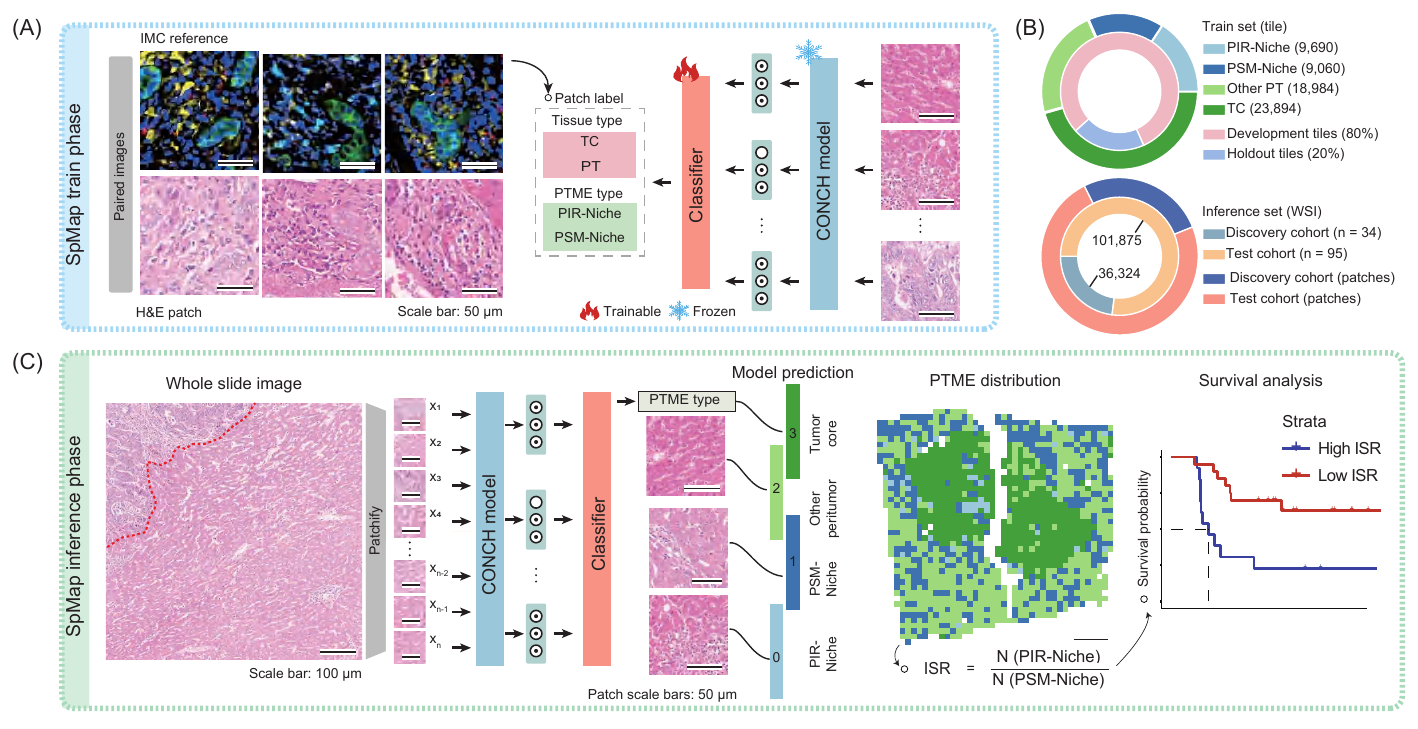

**Figure 5. SpMap translates spatial proteomic labels to H&E images.** (A) Paired IMC reference images and H&E patches supply tissue and niche labels for a classifier using frozen CONCH features. (B) Published reference-tile composition and development/holdout split, together with discovery/test inference cohort and tile totals. (C) Whole-slide tile classification, predicted spatial distribution, and PIR-Niche/PSM-Niche tile-count ratio for ISR-based survival stratification. Tiles measure 256 × 256 pixels at 20× magnification and 0.5 μm/pixel. Scale bars: 50 μm in A and the H&E tiles in C; 100 μm in the whole-slide view in C.

[Original Figure 5 PDF](report_assets/figure5_publication.pdf).


## 4. Public SpMap artifact export

[03_prepare_public_spmap_artifacts.py](03_prepare_public_spmap_artifacts.py) reads canonical labels, primary and five-fold split manifests, five selected evaluation runs, the final `primary_1280` run, and canonical CONCH feature shards. It writes two compressed label/partition tables, two metric tables, and three archives containing OOF predictions, five final fold checkpoints with portable manifests, and features.

Labels and partitions retain tile and parent-group units. Performance and OOF files retain seed/fold identities; each final model archive member identifies a fold-specific checkpoint. See the [public artifact index](../../docs/public_artifacts.md) for the released file contracts.


### Release inputs and evaluation identities

The configuration names canonical manifests, evaluation seeds, final-model input, feature shards, and the public output directory.

[Source: 03_prepare_public_spmap_artifacts.py (lines 1–47)](03_prepare_public_spmap_artifacts.py)


In [ ]:
#!/usr/bin/env python3
"""Prepare SpMap labels, partitions, metrics, predictions, and model archives.

Target/purpose: convert the selected SpMap evaluation and final-model artifacts
to portable public files. Inputs: canonical tile and split manifests, five
evaluation run directories, the primary 1,280-input run, and canonical
CONCH feature shards set in ``CONFIG``. Outputs: two compressed TSVs, two metric
TSVs, and three tar.gz archives in ``output_dir``. Ordered workflow: reconcile
labels and grouped partitions, collect saved metrics, validate each seed's
out-of-fold coverage, and package those predictions together with the five
primary fold checkpoints and canonical feature shards.
"""

from __future__ import annotations

import io
import json
import tarfile
from pathlib import Path

import numpy as np
import pandas as pd


CLASS_NAMES = {0: "TC", 1: "PIR", 2: "PSM", 3: "OTHER_PT"}
SEEDS = (24, 101, 202, 303, 404)
FOLDS = (1, 2, 3, 4, 5)

# Edit these paths before running this interactive Figure 5 entry point.
CONFIG = {
    "tile_manifest": Path("/path/to/tile_labels_canonical.csv"),
    "development": Path("/path/to/development.csv"),
    "holdout": Path("/path/to/internal_holdout.csv"),
    "validation_fold_dir": Path("/path/to/five_fold"),
    "seed_runs": {
        24: Path("/path/to/C10"),
        101: Path("/path/to/seed101"),
        202: Path("/path/to/seed202"),
        303: Path("/path/to/seed303"),
        404: Path("/path/to/seed404"),
    },
    "primary_run": Path("/path/to/primary_1280"),
    "conch_features": Path("/path/to/03_conch_features"),
    "output_dir": Path("/path/to/derived_results/SpMap"),
}




### Public labels and grouped partitions

Input readers normalize tile identifiers and construct primary-partition and validation-fold membership for every reference tile.

[Source: 03_prepare_public_spmap_artifacts.py (lines 48–162)](03_prepare_public_spmap_artifacts.py)


In [ ]:
def _require_columns(frame: pd.DataFrame, columns: set[str], path: Path) -> None:
    """Fail when an input table lacks required columns.

    Parameters: ``frame`` is the loaded table, ``columns`` is the required set,
    and ``path`` identifies the source in an error message.
    Returns: no value; raises ``ValueError`` for missing columns.
    """
    # Validate the source boundary before normalizing legacy field names.
    missing = columns - set(frame.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")


def read_tile_manifest(path: Path) -> pd.DataFrame:
    """Read the canonical four-class tile-label manifest.

    Parameters: ``path`` identifies the canonical label CSV.
    Returns: a validated dataframe with tile, class, and parent identifiers.
    """
    # Retain only the public fields required for split and prediction matching.
    frame = pd.read_csv(path)
    _require_columns(frame, {"tile_id", "class_id", "class_name", "parent_id"}, path)
    frame = frame[["tile_id", "class_id", "class_name", "parent_id"]].copy()
    frame["tile_id"] = frame["tile_id"].astype(str)
    frame["parent_id"] = frame["parent_id"].astype(str)
    frame["class_id"] = frame["class_id"].astype(int)
    if len(frame) != 61628 or frame["tile_id"].duplicated().any():
        raise ValueError("Canonical tile manifest must contain 61,628 unique tiles")
    expected_names = frame["class_id"].map(CLASS_NAMES)
    if expected_names.isna().any() or not expected_names.eq(frame["class_name"]).all():
        raise ValueError("Tile class IDs and names do not match the four-class contract")
    return frame


def read_split(path: Path) -> pd.DataFrame:
    """Read one legacy or normalized SpMap split manifest.

    Parameters: ``path`` identifies a development, holdout, or validation CSV.
    Returns: a dataframe normalized to tile_id, class_id, and parent_id.
    """
    # Current saved splits use fileName/type_num; public exports use canonical names.
    frame = pd.read_csv(path)
    if {"fileName", "type_num", "parent_id"}.issubset(frame.columns):
        frame = frame.rename(columns={"fileName": "tile_id", "type_num": "class_id"})
    _require_columns(frame, {"tile_id", "class_id", "parent_id"}, path)
    frame = frame[["tile_id", "class_id", "parent_id"]].copy()
    frame["tile_id"] = frame["tile_id"].astype(str)
    frame["parent_id"] = frame["parent_id"].astype(str)
    frame["class_id"] = frame["class_id"].astype(int)
    if frame["tile_id"].duplicated().any():
        raise ValueError(f"{path} contains duplicate tile IDs")
    return frame


def build_partitions(
    manifest: pd.DataFrame,
    development_path: Path,
    holdout_path: Path,
    validation_fold_dir: Path,
) -> pd.DataFrame:
    """Combine primary and five-fold memberships in one tile partition table.

    Parameters: ``manifest`` is canonical; the remaining paths identify saved
    development, holdout, and validation-fold manifests.
    Returns: all 61,628 tiles with primary_partition and validation_fold.
    """
    # The primary split partitions every canonical tile exactly once.
    development = read_split(development_path)
    holdout = read_split(holdout_path)
    combined = pd.concat(
        [
            development.assign(primary_partition="development"),
            holdout.assign(primary_partition="internal_holdout"),
        ],
        ignore_index=True,
    )
    if len(development) != 49001 or len(holdout) != 12627:
        raise ValueError("Expected 49,001 development and 12,627 holdout tiles")
    if combined["tile_id"].duplicated().any() or set(combined["tile_id"]) != set(manifest["tile_id"]):
        raise ValueError("Development and holdout must partition the canonical tiles")
    if set(development["parent_id"]) & set(holdout["parent_id"]):
        raise ValueError("Development and holdout parent groups must be disjoint")

    # Each development tile appears in one saved validation fold.
    fold_rows = []
    for fold in FOLDS:
        frame = read_split(validation_fold_dir / f"val_fold{fold}.csv")
        fold_rows.append(frame.assign(validation_fold=fold))
    folds = pd.concat(fold_rows, ignore_index=True)
    if folds["tile_id"].duplicated().any() or set(folds["tile_id"]) != set(development["tile_id"]):
        raise ValueError("Five validation folds must partition the development tiles")

    result = manifest.merge(
        combined[["tile_id", "class_id", "parent_id", "primary_partition"]],
        on="tile_id",
        how="left",
        suffixes=("", "_split"),
        validate="one_to_one",
    )
    if not result["class_id"].eq(result["class_id_split"]).all() or not result["parent_id"].eq(result["parent_id_split"]).all():
        raise ValueError("Primary split labels do not match the canonical manifest")
    result = result.drop(columns=["class_id_split", "parent_id_split"]).merge(
        folds[["tile_id", "validation_fold"]],
        on="tile_id",
        how="left",
        validate="one_to_one",
    )
    result["validation_fold"] = result["validation_fold"].astype("Int64")
    if result.loc[result["primary_partition"] == "development", "validation_fold"].isna().any():
        raise ValueError("Every development tile must have a validation-fold assignment")
    if result.loc[result["primary_partition"] == "internal_holdout", "validation_fold"].notna().any():
        raise ValueError("Internal-holdout tiles must not have a validation fold")
    return result




### Saved performance and OOF coverage

Metric collection preserves class and seed identities. OOF validation reconciles each seed’s predictions to the development tiles and their labels.

[Source: 03_prepare_public_spmap_artifacts.py (lines 163–269)](03_prepare_public_spmap_artifacts.py)


In [ ]:
def read_seed_metrics(seed_runs: dict[int, Path]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Collect saved class-specific and overall metrics for five seeds.

    Parameters: ``seed_runs`` maps the specified seeds to selected run roots.
    Returns: tidy performance rows and the seed-24 long confusion table.
    """
    # Convert saved wide summaries to one inspectable metric-value table.
    metric_rows: list[dict[str, object]] = []
    seed24_counts: pd.DataFrame | None = None
    seed24_rows: pd.DataFrame | None = None
    for seed in SEEDS:
        root = seed_runs[seed] / "comment12_summary"
        class_frame = pd.read_csv(root / "pooled_oof_per_class_metrics.csv")
        overall = pd.read_csv(root / "pooled_oof_metrics.csv")
        _require_columns(
            class_frame,
            {"class_id", "class_name", "support", "precision", "recall", "f1", "auroc_ovr", "auprc_ovr"},
            root / "pooled_oof_per_class_metrics.csv",
        )
        if len(class_frame) != 4 or len(overall) != 1:
            raise ValueError(f"Seed {seed} metric summaries have unexpected row counts")
        for row in class_frame.itertuples(index=False):
            for metric in ("precision", "recall", "f1", "auroc_ovr", "auprc_ovr"):
                metric_rows.append(
                    {
                        "seed": seed,
                        "scope": "class",
                        "class_name": row.class_name,
                        "support": int(row.support),
                        "metric": metric,
                        "value": float(getattr(row, metric)),
                    }
                )
        overall_metrics = {
            "accuracy": "accuracy",
            "precision_macro": "macro_precision",
            "recall_macro": "macro_recall",
            "f1_macro": "macro_f1",
            "auroc_macro_ovr": "macro_auroc_ovr",
            "auprc_macro_ovr": "macro_auprc_ovr",
            "auprc_pir_psm_mean": "pir_psm_mean_auprc",
        }
        for source, public_name in overall_metrics.items():
            metric_rows.append(
                {
                    "seed": seed,
                    "scope": "overall",
                    "class_name": "ALL",
                    "support": int(overall.iloc[0]["rows"]),
                    "metric": public_name,
                    "value": float(overall.iloc[0][source]),
                }
            )
        if seed == 24:
            seed24_counts = pd.read_csv(root / "pooled_oof_confusion_counts.csv", index_col=0)
            seed24_rows = pd.read_csv(root / "pooled_oof_confusion_row_normalized.csv", index_col=0)

    if seed24_counts is None or seed24_rows is None:
        raise ValueError("Seed 24 confusion summaries were not loaded")
    if list(seed24_counts.index) != list(CLASS_NAMES.values()) or list(seed24_counts.columns) != list(CLASS_NAMES.values()):
        raise ValueError("Seed 24 confusion table does not use the canonical class order")
    confusion_rows = []
    for true_class in CLASS_NAMES.values():
        for predicted_class in CLASS_NAMES.values():
            confusion_rows.append(
                {
                    "seed": 24,
                    "true_class": true_class,
                    "predicted_class": predicted_class,
                    "count": int(seed24_counts.loc[true_class, predicted_class]),
                    "true_class_fraction": float(seed24_rows.loc[true_class, predicted_class]),
                }
            )
    return pd.DataFrame(metric_rows), pd.DataFrame(confusion_rows)


def validate_oof_predictions(seed_runs: dict[int, Path], development: pd.DataFrame) -> None:
    """Validate complete out-of-fold coverage for every selected seed.

    Parameters: ``seed_runs`` maps seeds to run roots and ``development`` is the
    public partition table restricted to development tiles.
    Returns: no value; raises ``ValueError`` for incomplete or inconsistent OOF data.
    """
    # Each seed's five validation files must cover every development tile once.
    expected = development.set_index("tile_id")[["class_id", "parent_id"]].sort_index()
    for seed in SEEDS:
        frames = []
        for fold in FOLDS:
            path = seed_runs[seed] / f"fold{fold}" / "validation_predictions.csv"
            frame = pd.read_csv(path)
            _require_columns(
                frame,
                {"fileName", "type_num", "parent_id", "pred_class", "prob_tc", "prob_pir", "prob_psm", "prob_other_pt"},
                path,
            )
            frames.append(frame.rename(columns={"fileName": "tile_id", "type_num": "class_id"}))
        pooled = pd.concat(frames, ignore_index=True)
        if len(pooled) != 49001 or pooled["tile_id"].duplicated().any():
            raise ValueError(f"Seed {seed} must provide 49,001 unique OOF predictions")
        observed = pooled.set_index("tile_id")[["class_id", "parent_id"]].sort_index()
        if not observed.equals(expected):
            raise ValueError(f"Seed {seed} OOF labels do not match the development partition")
        probabilities = pooled[["prob_tc", "prob_pir", "prob_psm", "prob_other_pt"]].to_numpy(dtype=float)
        if not np.isfinite(probabilities).all() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-6):
            raise ValueError(f"Seed {seed} OOF probabilities must be finite and sum to one")




### Portable final-model manifests

The manifest helpers retain the final model architecture, training parameters, checkpoint-selection information, and saved evaluation summaries.

[Source: 03_prepare_public_spmap_artifacts.py (lines 270–358)](03_prepare_public_spmap_artifacts.py)


In [ ]:
def _add_bytes(archive: tarfile.TarFile, arcname: str, content: bytes) -> None:
    """Add generated bytes to a tar archive under a portable name.

    Parameters: ``archive`` is open for writing, ``arcname`` is the member name,
    and ``content`` is the serialized payload.
    Returns: no value after adding one archive member.
    """
    # Generated manifests are written directly without temporary filesystem files.
    member = tarfile.TarInfo(arcname)
    member.size = len(content)
    archive.addfile(member, io.BytesIO(content))


def public_model_manifest(path: Path, fold: int) -> dict[str, object]:
    """Select portable training metadata from one saved run manifest.

    Parameters: ``path`` identifies a private saved manifest and ``fold``
    identifies the public primary-model member.
    Returns: a dictionary containing portable model and training fields.
    """
    # Keep only the fixed model contract and portable numeric run summaries.
    source = json.loads(path.read_text(encoding="utf-8"))
    parameters = source.get("parameters")
    metric_names = ("accuracy", "precision_macro", "recall_macro", "f1_macro")
    if not isinstance(parameters, dict):
        raise ValueError(f"{path} must contain a parameters mapping")
    if source.get("fold") != fold:
        raise ValueError(f"{path} does not match fold {fold}")
    if (
        source.get("feature_mode") != "concat_1280"
        or source.get("input_dim") != 1280
        or source.get("class_map") != {str(index): name for index, name in CLASS_NAMES.items()}
        or source.get("architecture") != [1280, 450, 4]
        or source.get("activation") != "ReLU"
        or source.get("dropout") != 0.25
        or source.get("loss") != "inverse-frequency weighted cross-entropy"
        or source.get("optimizer") != "AdamW"
        or parameters.get("select_metric") != "accuracy"
        or source.get("terminal_evaluation_role") != "common_internal_holdout"
    ):
        raise ValueError(f"{path} does not satisfy the primary_1280 model contract")

    def portable_metrics(name: str) -> dict[str, float]:
        metrics = source.get(name)
        if not isinstance(metrics, dict) or set(metric_names) - set(metrics):
            raise ValueError(f"{path} is missing {name} fields")
        result = {metric: float(metrics[metric]) for metric in metric_names}
        if not np.isfinite(list(result.values())).all():
            raise ValueError(f"{path} has non-finite {name} values")
        return result

    parameter_names = ("batch", "epochs", "learning_rate", "weight_decay", "seed")
    if set(parameter_names) - set(parameters):
        raise ValueError(f"{path} is missing portable training parameters")
    selected_value = float(source["best_selection_value"])
    if not np.isfinite(selected_value):
        raise ValueError(f"{path} has a non-finite best_selection_value")
    return {
        "model_id": f"spmap_primary_1280_fold{fold}",
        "model_run": "primary_1280",
        "fold": fold,
        "seed": int(parameters["seed"]),
        "feature_mode": "paired_768_plus_512",
        "feature_dimensions": {"semantic": 768, "alignment": 512},
        "input_dim": 1280,
        "class_map": {str(index): name for index, name in CLASS_NAMES.items()},
        "architecture": [1280, 450, 4],
        "activation": "ReLU",
        "dropout": 0.25,
        "depth": 1,
        "batch_norm": False,
        "loss": "inverse-frequency weighted cross-entropy",
        "optimizer": "AdamW",
        "parameters": {
            "batch": int(parameters["batch"]),
            "epochs": int(parameters["epochs"]),
            "learning_rate": float(parameters["learning_rate"]),
            "weight_decay": float(parameters["weight_decay"]),
            "select_metric": "validation_accuracy",
        },
        "checkpoint_selection": "validation_accuracy",
        "selected_epoch": int(source["selected_epoch"]),
        "best_selection_value": selected_value,
        "validation_metrics": portable_metrics("validation_metrics"),
        "holdout_metrics": portable_metrics("holdout_metrics"),
        "terminal_evaluation_role": "common_internal_holdout",
    }




### Prediction, model, and feature archives

Archive writers organize 25 seed/fold prediction files, five final checkpoints with manifests, and the canonical feature shards under portable member paths.

[Source: 03_prepare_public_spmap_artifacts.py (lines 359–415)](03_prepare_public_spmap_artifacts.py)


In [ ]:
def write_prediction_archive(seed_runs: dict[int, Path], output: Path) -> None:
    """Archive the 25 selected validation-prediction tables.

    Parameters: ``seed_runs`` maps seeds to selected run roots and ``output`` is
    the target tar.gz path.
    Returns: no value after writing the archive.
    """
    # Seed/fold member paths retain the public evaluation hierarchy.
    with tarfile.open(output, "w:gz") as archive:
        for seed in SEEDS:
            for fold in FOLDS:
                source = seed_runs[seed] / f"fold{fold}" / "validation_predictions.csv"
                archive.add(source, arcname=f"seed{seed}/fold{fold}/validation_predictions.csv")


def write_weight_archive(primary_run: Path, output: Path) -> None:
    """Archive five primary fold checkpoints with portable model manifests.

    Parameters: ``primary_run`` is the selected 1,280-input run root and
    ``output`` is the target tar.gz path.
    Returns: no value after writing the archive.
    """
    # Every primary checkpoint is paired with portable model/training metadata.
    with tarfile.open(output, "w:gz") as archive:
        for fold in FOLDS:
            fold_root = primary_run / f"fold{fold}"
            prefix = f"fold{fold}"
            checkpoint = fold_root / "best.pt"
            manifest_path = fold_root / "run_manifest.json"
            if not checkpoint.is_file() or not manifest_path.is_file():
                raise FileNotFoundError(f"Fold {fold} is missing best.pt or run_manifest.json")
            archive.add(checkpoint, arcname=f"{prefix}/best.pt")
            manifest = public_model_manifest(manifest_path, fold)
            content = json.dumps(manifest, indent=2, sort_keys=True).encode("utf-8")
            _add_bytes(archive, f"{prefix}/model_manifest.json", content)


def write_feature_archive(source_root: Path, output: Path) -> None:
    """Archive canonical CONCH tar shards and member inventories.

    Parameters: ``source_root`` is the canonical feature directory and
    ``output`` is the target tar.gz path.
    Returns: no value after writing feature files under portable member paths.
    """
    # Package the actual feature shards and text member lists in sorted order.
    sources = sorted(
        path
        for path in source_root.rglob("*")
        if path.is_file() and (path.suffix == ".tar" or path.name == "archive_members.txt")
    )
    if not sources:
        raise ValueError("No canonical CONCH feature shards were found")
    with tarfile.open(output, "w:gz") as archive:
        for source in sources:
            archive.add(source, arcname=str(Path("SpMap_CONCH_features") / source.relative_to(source_root)))




### Public table and archive export

The entry point reconciles labels, partitions, and predictions before writing the seven public artifacts.

[Source: 03_prepare_public_spmap_artifacts.py (lines 416–468)](03_prepare_public_spmap_artifacts.py)


In [ ]:
def run(config: dict[str, object]) -> None:
    """Write all public SpMap artifacts from editable configuration.

    Parameters: ``config`` supplies label, split, run, feature, and output paths.
    Returns: no value; writes seven public release artifacts.
    """
    # Reconcile public labels and split membership before packaging model outputs.
    seed_runs = config["seed_runs"]
    if set(seed_runs) != set(SEEDS):
        raise ValueError("seed_runs must define seeds 24, 101, 202, 303, and 404")
    manifest = read_tile_manifest(config["tile_manifest"])
    partitions = build_partitions(
        manifest,
        config["development"],
        config["holdout"],
        config["validation_fold_dir"],
    )
    performance, confusion = read_seed_metrics(seed_runs)
    development = partitions.loc[partitions["primary_partition"] == "development"]
    validate_oof_predictions(seed_runs, development)

    output_dir = config["output_dir"]
    output_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(
        output_dir / "SpMap_reference_tile_labels.tsv.gz",
        sep="\t",
        index=False,
        compression="gzip",
    )
    partitions.to_csv(
        output_dir / "SpMap_tile_partitions.tsv.gz",
        sep="\t",
        index=False,
        compression="gzip",
    )
    performance.to_csv(output_dir / "SpMap_model_performance_5seeds.tsv", sep="\t", index=False)
    confusion.to_csv(output_dir / "SpMap_confusion_matrix.tsv", sep="\t", index=False)
    write_prediction_archive(
        seed_runs, output_dir / "SpMap_OOF_predictions_C10_5seeds_5folds.tar.gz"
    )
    write_weight_archive(
        config["primary_run"],
        output_dir / "SpMap_model_weights_primary_1280_5folds.tar.gz",
    )
    write_feature_archive(
        config["conch_features"], output_dir / "SpMap_CONCH_features.tar.gz"
    )
    for path in sorted(output_dir.iterdir()):
        print(path)


if __name__ == "__main__":
    run(CONFIG)


## 5. Supplementary Figure 11B–C: OOF and five-seed performance

[02_plot_oof_class_metrics.py](supplementary/FigureS11/02_plot_oof_class_metrics.py) consumes pooled OOF confusion counts and row proportions plus class-specific and overall metric tables for seeds 24, 101, 202, 303, and 404. Outputs are confusion and class-performance PDFs with plotted-data and interval TSVs.

The confusion matrix summarizes 49,001 OOF tiles. Class-specific precision, recall, one-versus-rest AUROC and AUPRC, and overall macro-F1 are summarized across five seeds with two-sided 95% t intervals. S11A’s fold-validation/common-holdout mean ± SD presentation is described in the [Figure 5 report](Figure5.md#a-fold-validation-and-common-holdout-metrics) and its [R source](supplementary/FigureS11/01_plot_fold_holdout_metrics.R).


### Metric definitions, encodings, and paths

The source sets the canonical class order, training seeds, displayed metrics, and four input-table paths.

[Source: supplementary/FigureS11/02_plot_oof_class_metrics.py (lines 1–42)](supplementary/FigureS11/02_plot_oof_class_metrics.py)


In [ ]:
#!/usr/bin/env python3
"""Plot Supplementary Figure 11B-C SpMap performance summaries.

Target/purpose: render the pooled OOF and five-seed summaries.
Inputs: the four small summary tables selected in ``CONFIG``. Outputs: two
PDFs and their plotted-data/statistics TSVs in the configured directory.
Ordered workflow: validate tables, calculate intervals, write normalized
tables, render the confusion panel, then render the class-performance panel.
"""

from __future__ import annotations

from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from scipy.stats import t


CLASS_ORDER = ["TC", "PIR", "PSM", "OTHER_PT"]
CLASS_LABELS = {"TC": "TC", "PIR": "PIR", "PSM": "PSM", "OTHER_PT": "Other PT"}
CLASS_COLORS = {"TC": "#555555", "PIR": "#3F8FB5", "PSM": "#E79A55", "OTHER_PT": "#A5A5A5"}
SEEDS = [24, 101, 202, 303, 404]
METRICS = [("precision", "Precision"), ("recall", "Recall"), ("auroc_ovr", "AUROC"), ("auprc_ovr", "AUPRC")]

# Edit these paths before running this interactive supplementary-figure entry point.
CONFIG = {
    "confusion_counts": Path("/path/to/confusion_counts.csv"),
    "confusion_row_proportions": Path("/path/to/confusion_row_proportions.csv"),
    "seed_class_metrics": Path("/path/to/seed_class_metrics.csv"),
    "seed_overall_metrics": Path("/path/to/seed_overall_metrics.csv"),
    "output_dir": Path("/path/to/FigureS11"),
}




### Confusion and seed-metric inputs

The readers reconcile counts with row proportions and arrange class and overall metrics on the specified seed grid.

[Source: supplementary/FigureS11/02_plot_oof_class_metrics.py (lines 43–122)](supplementary/FigureS11/02_plot_oof_class_metrics.py)


In [ ]:
def _read_matrix(path: Path, name: str) -> pd.DataFrame:
    """Read one class-indexed confusion matrix.

    Parameters: ``path`` is the CSV matrix and ``name`` identifies it in errors.
    Returns: a finite floating-point matrix in the fixed four-class order.
    """
    # Preserve the fixed true-class and predicted-class axes across both matrices.
    matrix = pd.read_csv(path, index_col=0)
    if list(matrix.index) != CLASS_ORDER or list(matrix.columns) != CLASS_ORDER:
        raise ValueError(f"{name} must use the exact class order {CLASS_ORDER}")
    matrix = matrix.astype(float)
    if not np.isfinite(matrix.to_numpy()).all():
        raise ValueError(f"{name} contains non-finite values")
    return matrix


def read_confusion(count_path: Path, proportion_path: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Read and validate the fixed 49,001-tile S11B confusion contract.

    Parameters: ``count_path`` and ``proportion_path`` identify the two CSVs.
    Returns: integer confusion counts and matching row-normalized proportions.
    """
    # Reconcile integer counts with their row-normalized plotting representation.
    counts = _read_matrix(count_path, "Confusion counts")
    if not np.equal(counts.to_numpy(), np.floor(counts.to_numpy())).all() or (counts.to_numpy() < 0).any():
        raise ValueError("Confusion counts must be non-negative integers")
    counts = counts.astype(int)
    if int(counts.to_numpy().sum()) != 49001:
        raise ValueError("Confusion counts must sum to 49,001 pooled OOF tiles")
    proportions = _read_matrix(proportion_path, "Confusion row proportions")
    if not np.allclose(proportions.sum(axis=1), 1.0, rtol=0, atol=1e-8):
        raise ValueError("Confusion row proportions must sum to one")
    expected = counts.div(counts.sum(axis=1), axis=0)
    if not np.allclose(proportions.to_numpy(), expected.to_numpy(), rtol=0, atol=1e-8):
        raise ValueError("Confusion row proportions do not match the count matrix")
    return counts, proportions


def read_seed_metrics(class_path: Path, overall_path: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Read the complete five-seed S11C metric tables.

    Parameters: ``class_path`` identifies class-level metrics and ``overall_path``
    identifies macro-F1 metrics.
    Returns: ordered class-level and overall five-seed dataframes.
    """
    # Map class-level metrics to the complete seed-by-class grid in display order.
    class_metrics = pd.read_csv(class_path)
    required_class = {"seed", "class_name", *(metric for metric, _ in METRICS)}
    missing_class = required_class - set(class_metrics.columns)
    if missing_class:
        raise ValueError(f"Seed class metrics are missing columns: {sorted(missing_class)}")
    class_metrics = class_metrics.copy()
    class_metrics["seed"] = class_metrics["seed"].astype(int)
    observed = set(zip(class_metrics["seed"], class_metrics["class_name"]))
    expected = {(seed, class_name) for seed in SEEDS for class_name in CLASS_ORDER}
    if observed != expected or len(class_metrics) != len(expected):
        raise ValueError("Seed class metrics must contain exactly one row per configured seed and class")
    class_metrics = class_metrics.set_index(["seed", "class_name"]).loc[
        pd.MultiIndex.from_product([SEEDS, CLASS_ORDER], names=["seed", "class_name"])
    ].reset_index()
    metric_columns = [metric for metric, _ in METRICS]
    if not np.isfinite(class_metrics[metric_columns].to_numpy()).all() or not ((class_metrics[metric_columns] >= 0) & (class_metrics[metric_columns] <= 1)).all().all():
        raise ValueError("Seed class metrics must be finite proportions")

    # Keep overall macro-F1 on the same ordered five-seed axis.
    overall_metrics = pd.read_csv(overall_path)
    required_overall = {"seed", "f1_macro"}
    missing_overall = required_overall - set(overall_metrics.columns)
    if missing_overall:
        raise ValueError(f"Seed overall metrics are missing columns: {sorted(missing_overall)}")
    overall_metrics = overall_metrics[["seed", "f1_macro"]].copy()
    overall_metrics["seed"] = overall_metrics["seed"].astype(int)
    overall_metrics = overall_metrics.sort_values("seed").reset_index(drop=True)
    if overall_metrics["seed"].tolist() != SEEDS or overall_metrics["seed"].duplicated().any():
        raise ValueError("Seed overall metrics must contain seeds 24, 101, 202, 303, and 404 once")
    if not np.isfinite(overall_metrics["f1_macro"]).all() or not overall_metrics["f1_macro"].between(0, 1).all():
        raise ValueError("Macro-F1 values must be finite proportions")
    return class_metrics, overall_metrics




### Intervals across training seeds

A shared two-sided 95% t-interval definition summarizes each class metric and overall macro-F1.

[Source: supplementary/FigureS11/02_plot_oof_class_metrics.py (lines 123–146)](supplementary/FigureS11/02_plot_oof_class_metrics.py)


In [ ]:
def interval_table(class_metrics: pd.DataFrame, overall_metrics: pd.DataFrame) -> pd.DataFrame:
    """Calculate two-sided 95% t intervals across the five specified seeds.

    Parameters: ``class_metrics`` and ``overall_metrics`` are validated seed tables.
    Returns: one interval row per class metric plus overall macro-F1.
    """
    # Apply one interval definition to every class metric and overall macro-F1.
    rows: list[dict[str, object]] = []
    critical = t.ppf(0.975, df=len(SEEDS) - 1)
    for metric, label in METRICS:
        for class_name in CLASS_ORDER:
            values = class_metrics.loc[class_metrics["class_name"] == class_name, metric].to_numpy(dtype=float)
            mean = float(values.mean())
            standard_deviation = float(values.std(ddof=1))
            margin = float(critical * standard_deviation / np.sqrt(len(values)))
            rows.append({"metric": label, "class_name": class_name, "seeds": len(values), "mean": mean, "standard_deviation": standard_deviation, "ci95_lower": mean - margin, "ci95_upper": mean + margin, "interval_definition": "two-sided t interval across five training seeds"})
    values = overall_metrics["f1_macro"].to_numpy(dtype=float)
    mean = float(values.mean())
    standard_deviation = float(values.std(ddof=1))
    margin = float(critical * standard_deviation / np.sqrt(len(values)))
    rows.append({"metric": "Macro-F1", "class_name": "overall", "seeds": len(values), "mean": mean, "standard_deviation": standard_deviation, "ci95_lower": mean - margin, "ci95_upper": mean + margin, "interval_definition": "two-sided t interval across five training seeds"})
    return pd.DataFrame(rows)




### Confusion and class-performance panels

The plotting functions display true-class row percentages with counts and place seed observations beside metric means and confidence intervals.

[Source: supplementary/FigureS11/02_plot_oof_class_metrics.py (lines 147–237)](supplementary/FigureS11/02_plot_oof_class_metrics.py)


In [ ]:
def plot_confusion(counts: pd.DataFrame, proportions: pd.DataFrame, output: Path) -> None:
    """Render the S11B four-class pooled OOF confusion PDF.

    Parameters: ``counts`` and ``proportions`` are validated confusion matrices;
    ``output`` is the target PDF path.
    Returns: no value; writes the PDF.
    """
    # Encode row percentages by color while retaining counts in each matrix cell.
    cmap = LinearSegmentedColormap.from_list("spmap_confusion", ["#F7F9FA", "#B8D5E5", "#3F8FB5", "#174A66"])
    figure, axis = plt.subplots(figsize=(4.45, 3.95))
    image = axis.imshow(proportions.to_numpy() * 100, cmap=cmap, vmin=0, vmax=100)
    labels = [CLASS_LABELS[name] for name in CLASS_ORDER]
    axis.set_xticks(range(4), labels=labels)
    axis.set_yticks(range(4), labels=labels)
    axis.set_xlabel("Predicted class", labelpad=7)
    axis.set_ylabel("True class", labelpad=7)
    axis.set_title("Four-class pooled out-of-fold confusion matrix", fontweight="bold", pad=10)
    axis.tick_params(axis="both", length=0, pad=5)
    axis.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, 4, 1), minor=True)
    axis.grid(which="minor", color="white", linewidth=1.2)
    axis.tick_params(which="minor", bottom=False, left=False)
    for ticks in (axis.get_xticklabels(), axis.get_yticklabels()):
        for tick, class_name in zip(ticks, CLASS_ORDER):
            tick.set_color(CLASS_COLORS[class_name])
            if class_name in ("PIR", "PSM"):
                tick.set_fontweight("bold")
    for row in range(4):
        for column in range(4):
            percentage = proportions.iloc[row, column] * 100
            axis.text(column, row, f"{counts.iloc[row, column]:,}\n({percentage:.1f}%)", ha="center", va="center", color="white" if percentage >= 42 else "#222222", fontsize=7.5, linespacing=1.25)
    axis.add_patch(Rectangle((0.5, 0.5), 2, 2, fill=False, edgecolor="#202020", linewidth=1.1, linestyle=(0, (3, 2))))
    colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.045)
    colorbar.set_label("True-class row percentage (%)", rotation=270, labelpad=13)
    colorbar.set_ticks([0, 25, 50, 75, 100])
    colorbar.outline.set_linewidth(0.5)
    axis.text(-0.20, 1.11, "B", transform=axis.transAxes, fontsize=11, fontweight="bold")
    figure.subplots_adjust(left=0.19, right=0.86, bottom=0.18, top=0.84)
    figure.savefig(output, format="pdf", bbox_inches="tight", metadata={"Title": "Supplementary Figure 11B four-class pooled OOF confusion matrix"})
    plt.close(figure)


def plot_performance(class_metrics: pd.DataFrame, overall_metrics: pd.DataFrame, intervals: pd.DataFrame, output: Path) -> None:
    """Render the S11C class-specific five-seed performance PDF.

    Parameters: ``class_metrics`` and ``overall_metrics`` supply observed values,
    ``intervals`` supplies t intervals, and ``output`` is the PDF path.
    Returns: no value; writes the PDF.
    """
    # Allocate stable metric and class offsets before adding seed values and intervals.
    metric_positions = {metric: position for position, (metric, _) in enumerate(METRICS)}
    class_offsets = dict(zip(CLASS_ORDER, [-0.24, -0.08, 0.08, 0.24]))
    seed_jitter = dict(zip(SEEDS, np.linspace(-0.025, 0.025, len(SEEDS))))
    figure, axis = plt.subplots(figsize=(7.2, 4.35))
    for metric, label in METRICS:
        for class_name in CLASS_ORDER:
            values = class_metrics.loc[class_metrics["class_name"] == class_name].set_index("seed").loc[SEEDS, metric].astype(float)
            x_position = metric_positions[metric] + class_offsets[class_name]
            for seed, value in values.items():
                axis.scatter(x_position + seed_jitter[seed], value, marker="x", s=19, color=CLASS_COLORS[class_name], linewidth=0.85, alpha=0.65, zorder=2)
            summary = intervals.loc[(intervals["metric"] == label) & (intervals["class_name"] == class_name)].iloc[0]
            axis.errorbar(x_position, summary["mean"], yerr=[[summary["mean"] - summary["ci95_lower"]], [summary["ci95_upper"] - summary["mean"]]], fmt="o", markersize=4.8, markerfacecolor=CLASS_COLORS[class_name], markeredgecolor="#202020", markeredgewidth=0.45, ecolor=CLASS_COLORS[class_name], elinewidth=1.35, capsize=2.8, capthick=1.0, zorder=3)
    # Plot overall macro-F1 separately from the four class-specific metric groups.
    macro_values = overall_metrics.set_index("seed").loc[SEEDS, "f1_macro"].astype(float)
    for seed, value in macro_values.items():
        axis.scatter(4 + seed_jitter[seed], value, marker="x", s=19, color="#222222", linewidth=0.85, alpha=0.65, zorder=2)
    macro = intervals.loc[intervals["metric"] == "Macro-F1"].iloc[0]
    axis.errorbar(4, macro["mean"], yerr=[[macro["mean"] - macro["ci95_lower"]], [macro["ci95_upper"] - macro["mean"]]], fmt="D", markersize=5.0, markerfacecolor="#222222", markeredgecolor="#222222", ecolor="#222222", elinewidth=1.35, capsize=2.8, capthick=1.0, zorder=3)
    axis.hlines(0.5, 2 - 0.44, 2 + 0.44, color="#777777", linewidth=1.0, linestyle=(0, (4, 3)), zorder=1)
    axis.text(2, 0.515, "Random AUROC = 0.5", color="#666666", fontsize=6.8, ha="center", va="bottom")
    axis.set_xlim(-0.55, 4.45)
    axis.set_ylim(0, 1.025)
    axis.set_xticks(range(5), [label for _, label in METRICS] + ["Macro-F1"])
    axis.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    axis.set_yticklabels(["0", ".25", ".50", ".75", "1"])
    axis.set_ylabel("Performance", labelpad=7)
    axis.grid(axis="y", color="#E2E2E2", linewidth=0.55)
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(axis="x", length=0, pad=7)
    axis.tick_params(axis="y", length=3, color="#444444")
    handles = [Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=CLASS_COLORS[name], markeredgecolor="#222222", markeredgewidth=0.4, markersize=5, label=CLASS_LABELS[name]) for name in CLASS_ORDER]
    handles.extend([Line2D([0], [0], marker="D", linestyle="none", markerfacecolor="#222222", markeredgecolor="#222222", markersize=5, label="Overall macro-F1"), Line2D([0], [0], linestyle=(0, (4, 3)), color="#777777", linewidth=1.0, label="Random AUROC")])
    axis.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.20), frameon=False, ncol=6, handlelength=1.4, handletextpad=0.45, columnspacing=1.0, fontsize=7.2)
    axis.set_title("Class-specific performance across five training seeds", fontsize=9, fontweight="bold", pad=45)
    axis.text(-0.09, 1.18, "C", transform=axis.transAxes, fontsize=11, fontweight="bold")
    figure.text(0.985, 0.025, "Crosses show individual seeds; circles/diamond show means; error bars are 95% t intervals across seeds.", fontsize=6.8, color="#555555", ha="right")
    figure.subplots_adjust(left=0.10, right=0.985, bottom=0.17, top=0.78)
    figure.savefig(output, format="pdf", bbox_inches="tight", metadata={"Title": "Supplementary Figure 11C class-specific performance across training seeds"})
    plt.close(figure)




### Supplementary metric exports

The entry point writes the normalized plotting tables, interval statistics, and two panel PDFs.

[Source: supplementary/FigureS11/02_plot_oof_class_metrics.py (lines 238–264)](supplementary/FigureS11/02_plot_oof_class_metrics.py)


In [ ]:
def run(config: dict[str, Path]) -> None:
    """Write and plot S11B-C outputs from editable in-script configuration.

    Parameters: ``config`` supplies the four input CSV paths and ``output_dir``.
    Returns: no value; writes the configured TSV and PDF artifacts.
    """
    # Orchestrate metric preparation, normalized table export, and both figure panels.
    counts, proportions = read_confusion(
        config["confusion_counts"], config["confusion_row_proportions"]
    )
    class_metrics, overall_metrics = read_seed_metrics(
        config["seed_class_metrics"], config["seed_overall_metrics"]
    )
    intervals = interval_table(class_metrics, overall_metrics)
    output_dir = config["output_dir"]
    output_dir.mkdir(parents=True, exist_ok=True)
    counts.rename_axis("true_class").reset_index().to_csv(output_dir / "FigureS11B_confusion_counts.tsv", sep="\t", index=False)
    proportions.rename_axis("true_class").reset_index().to_csv(output_dir / "FigureS11B_confusion_row_proportions.tsv", sep="\t", index=False)
    class_metrics.to_csv(output_dir / "FigureS11C_seed_class_metrics.tsv", sep="\t", index=False)
    overall_metrics.to_csv(output_dir / "FigureS11C_seed_macro_f1.tsv", sep="\t", index=False)
    intervals.to_csv(output_dir / "FigureS11C_metric_t_intervals.tsv", sep="\t", index=False)
    plot_confusion(counts, proportions, output_dir / "FigureS11B_confusion_matrix.pdf")
    plot_performance(class_metrics, overall_metrics, intervals, output_dir / "FigureS11C_class_metrics.pdf")


if __name__ == "__main__":
    run(CONFIG)


## 6. Supplementary Figure 11D: matched-patient ISR correlation

[03_plot_isr_correlation.py](supplementary/FigureS11/03_plot_isr_correlation.py) consumes unique-patient IMC and H&E ISR tables and pairs 33 discovery-cohort patients by a one-to-one inner join. The IMC score is `(n_bdme_i + 1) / (n_bdme_s + 1)`, clipped to `[0.1, 10]`; the H&E score is `bile_1_count / bile_2_count`.

Outputs are a matched-patient TSV, a statistics TSV, and `FigureS11D_isr_correlation.pdf`. Pearson correlation uses a two-sided nominal P value and a Fisher-z 95% interval. The display includes an ordinary least-squares line and a pointwise 95% confidence band for its fitted mean.


### Patient-score inputs and output paths

The source declares the expected matched-patient count and the two score-table paths.

[Source: supplementary/FigureS11/03_plot_isr_correlation.py (lines 1–33)](supplementary/FigureS11/03_plot_isr_correlation.py)


In [ ]:
#!/usr/bin/env python3
"""Plot Supplementary Figure 11D from specified patient-level ISR score tables.

Target/purpose: correlate matched IMC-derived and H&E-derived ISR values.
Inputs: unique-PID IMC and unique-WSI H&E score CSVs set in ``CONFIG``.
Outputs: matched-patient/statistics TSVs and one PDF in ``output_dir``. Ordered
workflow: validate ISR arithmetic, perform the one-to-one join, calculate Pearson
statistics, write tables, and render the correlation panel.
"""

from __future__ import annotations

from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


EXPECTED_MATCHED_PATIENTS = 33

# Edit these paths before running this interactive supplementary-figure entry point.
CONFIG = {
    "imc_scores": Path("/path/to/imc_scores.csv"),
    "he_scores": Path("/path/to/he_scores.csv"),
    "output_dir": Path("/path/to/FigureS11"),
}




### Score definitions and one-to-one matching

Input helpers establish the score schema, Fisher-z interval definition, operational ISR arithmetic, and matched-patient table.

[Source: supplementary/FigureS11/03_plot_isr_correlation.py (lines 34–96)](supplementary/FigureS11/03_plot_isr_correlation.py)


In [ ]:
def _require_columns(frame: pd.DataFrame, columns: set[str], source: str) -> None:
    """Fail when an ISR input table lacks a required column.

    Parameters: ``frame`` is the loaded table, ``columns`` is the required set,
    and ``source`` identifies the table in errors.
    Returns: no value; raises ``ValueError`` when a column is absent.
    """
    # Establish the identifier, count, and saved-score fields used for matching.
    missing = columns - set(frame.columns)
    if missing:
        raise ValueError(f"{source} is missing columns: {sorted(missing)}")


def fisher_z_interval(r_value: float, n: int) -> tuple[float, float]:
    """Calculate a two-sided 95% Fisher-z interval for Pearson correlation.

    Parameters: ``r_value`` is the observed Pearson correlation and ``n`` is the
    matched-patient count.
    Returns: lower and upper correlation-scale confidence limits.
    """
    # The Fisher transform requires a non-perfect correlation and residual degrees of freedom.
    if n <= 3 or not -1 < r_value < 1:
        raise ValueError("Fisher-z confidence interval requires n > 3 and a non-perfect correlation")
    z_value = np.arctanh(r_value)
    margin = stats.norm.ppf(0.975) / np.sqrt(n - 3)
    return tuple(np.tanh([z_value - margin, z_value + margin]))


def load_and_match(imc_path: Path, he_path: Path) -> pd.DataFrame:
    """Validate source ISR arithmetic and create the specified one-to-one join.

    Parameters: ``imc_path`` and ``he_path`` identify the specified source CSVs.
    Returns: a sorted 33-patient dataframe containing both derived ISR values.
    """
    # Map each source to one identifier and its operational ISR definition.
    imc = pd.read_csv(imc_path)
    he = pd.read_csv(he_path)
    _require_columns(imc, {"PID", "n_bdme_i", "n_bdme_s", "easy_bdme_score"}, "IMC scores")
    _require_columns(he, {"wsi_id", "bile_1_count", "bile_2_count", "ratio_bile1_to_bile2"}, "H&E scores")
    if imc["PID"].duplicated().any() or he["wsi_id"].duplicated().any():
        raise ValueError("IMC PID and H&E wsi_id values must each be unique")
    imc = imc[["PID", "n_bdme_i", "n_bdme_s", "easy_bdme_score"]].copy()
    he = he[["wsi_id", "bile_1_count", "bile_2_count", "ratio_bile1_to_bile2"]].copy()
    numeric_imc = ["n_bdme_i", "n_bdme_s", "easy_bdme_score"]
    numeric_he = ["bile_1_count", "bile_2_count", "ratio_bile1_to_bile2"]
    if not np.isfinite(imc[numeric_imc].to_numpy(dtype=float)).all() or not np.isfinite(he[numeric_he].to_numpy(dtype=float)).all():
        raise ValueError("ISR score inputs must be finite")
    expected_imc = np.clip((imc["n_bdme_i"] + 1) / (imc["n_bdme_s"] + 1), 0.1, 10)
    if not np.allclose(imc["easy_bdme_score"], expected_imc, rtol=0, atol=1e-8):
        raise ValueError("Saved IMC ISR does not match the operational clipped pseudocount definition")
    if (he["bile_2_count"] == 0).any():
        raise ZeroDivisionError("H&E PSM tile count is zero")
    expected_he = he["bile_1_count"] / he["bile_2_count"]
    if not np.allclose(he["ratio_bile1_to_bile2"], expected_he, rtol=0, atol=1e-8):
        raise ValueError("Saved H&E ISR does not match the literal PIR/PSM ratio")
    # Preserve patient-level inference through an explicitly one-to-one inner match.
    matched = imc.merge(he, left_on="PID", right_on="wsi_id", how="inner", validate="one_to_one")
    if len(matched) != EXPECTED_MATCHED_PATIENTS:
        raise ValueError(f"Expected {EXPECTED_MATCHED_PATIENTS} matched discovery-cohort patients, found {len(matched)}")
    matched = matched.rename(columns={"easy_bdme_score": "imc_derived_isr", "ratio_bile1_to_bile2": "he_derived_isr"}).drop(columns="wsi_id")
    return matched.sort_values("PID").reset_index(drop=True)




### Patient-level correlation and fitted display

The statistics and plotting functions use paired patient vectors to report Pearson estimates and display the fitted mean with its confidence band.

[Source: supplementary/FigureS11/03_plot_isr_correlation.py (lines 97–151)](supplementary/FigureS11/03_plot_isr_correlation.py)


In [ ]:
def correlation_statistics(matched: pd.DataFrame) -> dict[str, object]:
    """Calculate the reported Pearson correlation and Fisher-z interval.

    Parameters: ``matched`` is the validated one-row-per-patient ISR dataframe.
    Returns: a statistics dictionary written to the S11D results TSV.
    """
    # Prepare paired patient vectors once for the correlation and confidence interval.
    x_values = matched["imc_derived_isr"].to_numpy(dtype=float)
    y_values = matched["he_derived_isr"].to_numpy(dtype=float)
    r_value, p_value = stats.pearsonr(x_values, y_values)
    ci_low, ci_high = fisher_z_interval(float(r_value), len(matched))
    return {"n": len(matched), "pearson_r": r_value, "pearson_p_two_sided": p_value, "pearson_ci95_low_fisher_z": ci_low, "pearson_ci95_high_fisher_z": ci_high, "imc_isr_definition": "clip((n_bdme_i + 1) / (n_bdme_s + 1), 0.1, 10)", "he_isr_definition": "bile_1_count / bile_2_count", "ci_definition": "two-sided 95% Fisher-z confidence interval"}


def plot_panel(matched: pd.DataFrame, summary: dict[str, object], output: Path) -> None:
    """Render the S11D patient-level ISR correlation PDF.

    Parameters: ``matched`` contains paired ISR values, ``summary`` contains
    correlation statistics, and ``output`` is the target PDF path.
    Returns: no value; writes the PDF.
    """
    # Fit the displayed ordinary least-squares mean and its pointwise confidence band.
    x_values = matched["imc_derived_isr"].to_numpy(dtype=float)
    y_values = matched["he_derived_isr"].to_numpy(dtype=float)
    n = len(matched)
    design = np.column_stack([np.ones(n), x_values])
    intercept, slope = np.linalg.lstsq(design, y_values, rcond=None)[0]
    x_grid = np.linspace(x_values.min(), x_values.max(), 300)
    fitted = intercept + slope * x_grid
    residuals = y_values - (intercept + slope * x_values)
    mse = np.sum(residuals ** 2) / (n - 2)
    sxx = np.sum((x_values - x_values.mean()) ** 2)
    if sxx == 0:
        raise ValueError("IMC ISR values must vary to plot the fitted mean confidence band")
    fit_se = np.sqrt(mse * (1 / n + (x_grid - x_values.mean()) ** 2 / sxx))
    critical = stats.t.ppf(0.975, df=n - 2)
    # Render paired patients, the fitted mean, and the reported correlation together.
    plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"], "font.size": 8, "axes.labelsize": 8.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "pdf.fonttype": 42, "ps.fonttype": 42})
    figure, axis = plt.subplots(figsize=(3.5, 3.15))
    axis.fill_between(x_grid, fitted - critical * fit_se, fitted + critical * fit_se, color="#B3B3B3", alpha=0.38, linewidth=0)
    axis.plot(x_grid, fitted, color="#333333", linewidth=1.25, zorder=2)
    axis.scatter(x_values, y_values, s=25, color="#0072B2", edgecolor="white", linewidth=0.5, alpha=0.9, zorder=3)
    annotation = f"Pearson r = {summary['pearson_r']:.3f}\n95% CI: {summary['pearson_ci95_low_fisher_z']:.3f} to {summary['pearson_ci95_high_fisher_z']:.3f}\nP = {summary['pearson_p_two_sided']:.2e}\nn = {summary['n']}"
    axis.text(0.04, 0.96, annotation, transform=axis.transAxes, ha="left", va="top", fontsize=7.5, linespacing=1.35)
    axis.set_xlabel("IMC-derived ISR")
    axis.set_ylabel("H&E-derived ISR")
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.tick_params(direction="out", length=3, width=0.7)
    axis.margins(x=0.05, y=0.08)
    figure.tight_layout(pad=0.8)
    figure.savefig(output, format="pdf", metadata={"Title": "Supplementary Figure 11D patient-level IMC and H&E ISR correlation"})
    plt.close(figure)




### Matched data, statistics, and panel export

The entry point writes the paired-patient data and correlation statistics before exporting the PDF.

[Source: supplementary/FigureS11/03_plot_isr_correlation.py (lines 152–169)](supplementary/FigureS11/03_plot_isr_correlation.py)


In [ ]:
def run(config: dict[str, Path]) -> None:
    """Write and plot S11D outputs from editable in-script configuration.

    Parameters: ``config`` supplies IMC/H&E score paths and ``output_dir``.
    Returns: no value; writes the matched table, statistics table, and PDF.
    """
    # Orchestrate matching, patient-level statistics, tabular export, and plotting.
    matched = load_and_match(config["imc_scores"], config["he_scores"])
    summary = correlation_statistics(matched)
    output_dir = config["output_dir"]
    output_dir.mkdir(parents=True, exist_ok=True)
    matched.to_csv(output_dir / "FigureS11D_matched_patient_isr.tsv", sep="\t", index=False)
    pd.DataFrame([summary]).to_csv(output_dir / "FigureS11D_correlation_statistics.tsv", sep="\t", index=False)
    plot_panel(matched, summary, output_dir / "FigureS11D_isr_correlation.pdf")


if __name__ == "__main__":
    run(CONFIG)


## Saved supplementary result — Supplementary Figure 11

The saved layout combines model-evaluation summaries, pooled OOF confusion, seed-level performance, and the paired-patient ISR comparison.

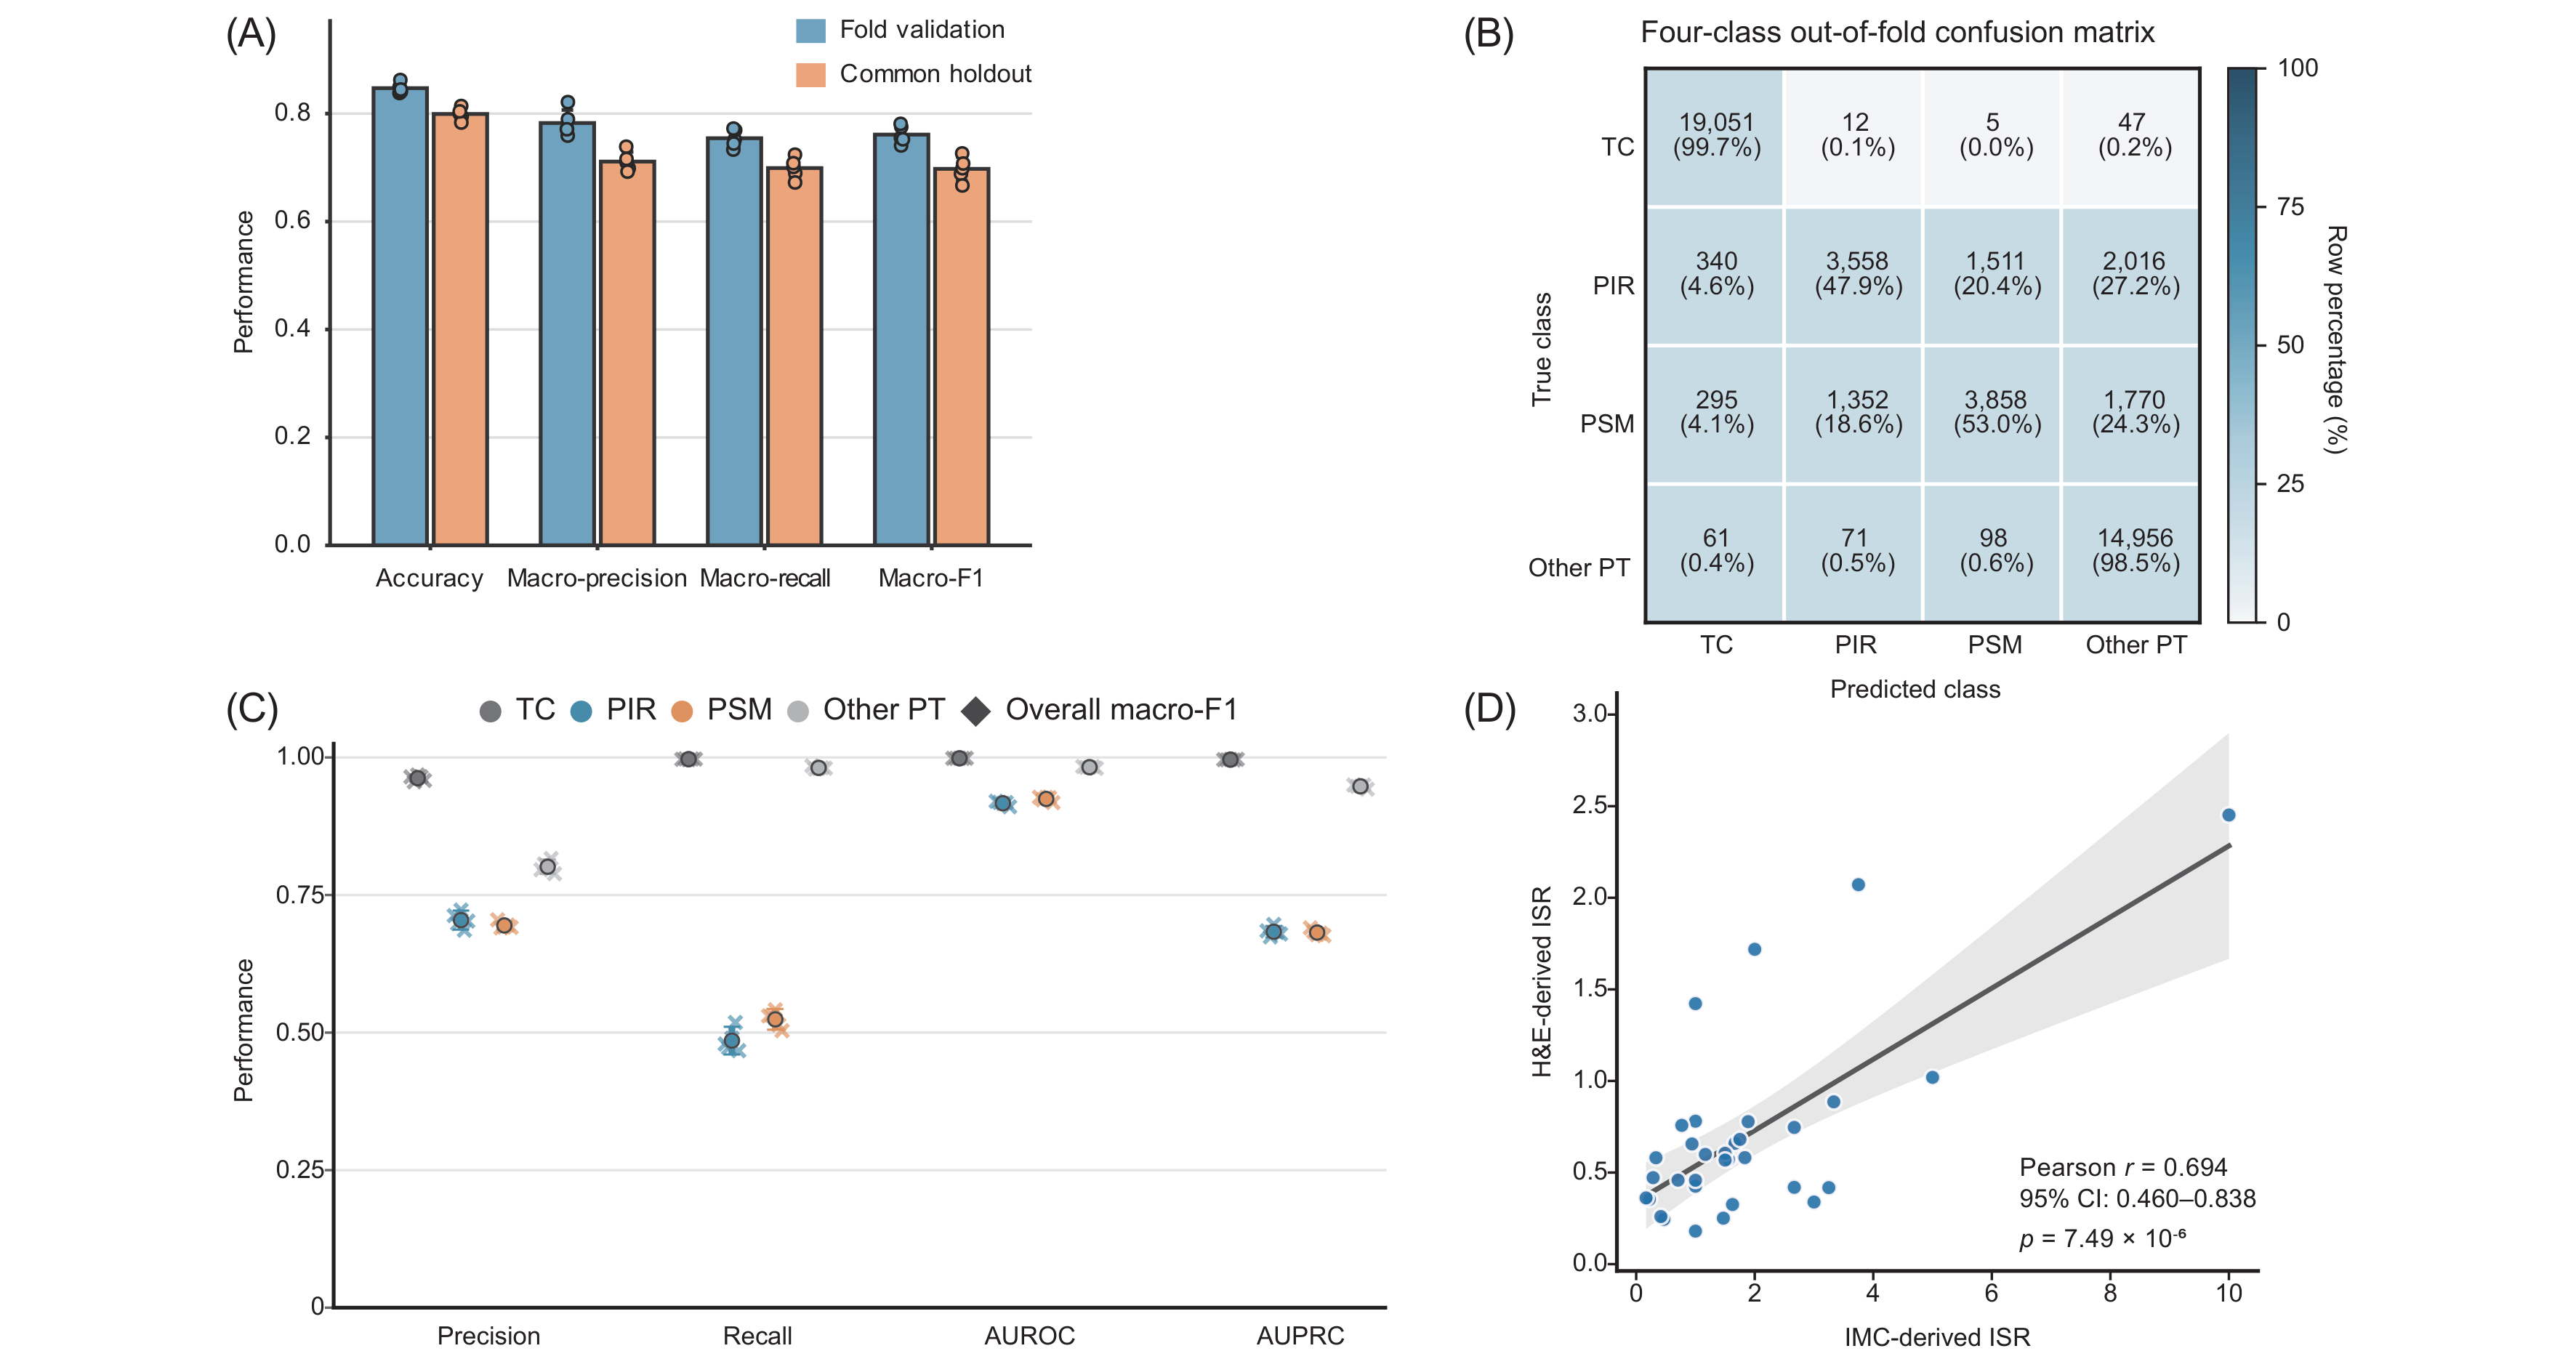

**Supplementary Figure 11. Internal evaluation of SpMap and patient-level comparison of IMC-derived and H&E-derived immune-stromal ratio.** (A) Accuracy, macro-precision, macro-recall, and macro-F1 for five fold-specific models; bars show means, error bars show SD, and points show model evaluations. (B) Seed-24 pooled OOF confusion counts and percentages within true-class rows. (C) Class-specific precision, recall, AUROC, and AUPRC across five seeds; crosses show seeds, circles show means, and error bars show 95% t intervals. (D) Paired ISR values with the fitted regression line, its 95% confidence band, and Pearson statistics.

Original component PDFs: [fold-validation/common-holdout metrics](report_assets/fold_holdout_metrics.pdf), [pooled OOF confusion](report_assets/oof_confusion.pdf), and [five-seed performance](report_assets/five_seed_performance.pdf).


## Related reading and shared implementation

The [owning README](README.md) specifies the figure entry points and file schemas; [Figure5.md](Figure5.md) presents the accompanying scientific report. The [display guide](../../docs/rmd_display.md) links the complete figure collection.

The [shared SpMap library](../../src/spmap/README.md) documents [reference tiling](../../src/spmap/reference_tiles.py), [preprocessing](../../src/spmap/preprocessing.py), [CONCH feature extraction](../../src/spmap/conch_features.py), [grouped splits](../../src/spmap/splits.py), [MLP training and evaluation](../../src/spmap/mlp.py), [WSI reading](../../src/spmap/wsi.py), [tile inference](../../src/spmap/inference.py), and [WSI ISR aggregation](../../src/spmap/isr.py).
